# BÁO CÁO MÔ HÌNH HÓA ĐỊNH GIÁ BẤT ĐỘNG SẢN TP.HCM (HEDONIC PRICE MODELING)
**Môn học:** Lập trình Phân tích Dữ liệu  
**Phương pháp:** Pipeline tiền xử lý 351 chiều, Khử chệch Jensen qua Duan's Smearing Factor, Đối chuẩn 4 Thuật toán Học máy và Đánh giá Thực nghiệm 7 Tỷ lệ Phân chia Train/Test.

---
### MỤC LỤC TỔNG QUAN NOTEBOOK:
1. **Thư viện & Cấu hình môi trường**
2. **Nạp dữ liệu & Tiền xử lý (Pipeline chuẩn hóa & One-Hot 351 chiều)**
3. **Hàm đánh giá & Khử chệch Jensen qua Duan's Smearing Factor**
4. **Mô hình Cơ sở (Baseline Heuristic)**
5. **Hồi quy Tuyến tính Cổ điển (Linear Regression - OLS)**
6. **Hồi quy Ridge (Regularized Ridge Regression)**
7. **Rừng Ngẫu nhiên (Random Forest Regressor)**
8. **Tăng cường Độ dốc (Gradient Boosting Regressor - GBR)**
9. **Hàm tổng hợp huấn luyện toàn bộ mô hình (Master Runner Function)**
10. **Thực thi huấn luyện toàn bộ mô hình trên Tỷ lệ Chuẩn 80/20**
11. **Bảng Kết quả So sánh Mô hình với Baseline (Master Table 5 Cột)**
12. **Trực quan hóa kết quả (3 Tiêu chí số cốt lõi & Top 10 đặc trưng GBR)**
13. **Phân tích Chuyên sâu & Trả lời các Câu hỏi Nghiên cứu Thực nghiệm**
    - *13.1. Câu hỏi 2: Mức thặng dư định giá của 19 Quận/Huyện tại TP.HCM (Ridge)*
    - *13.2. Câu hỏi 3: So sánh mức chênh lệch giá giữa tin Chính chủ và Môi giới*
    - *13.3. Câu hỏi 4: Tác động biên của tiện ích & pháp lý (Mặt tiền, Hẻm ô tô, Sổ hồng, Nội thất)*
    - *13.4. Câu hỏi 5: Đối chiếu mặt bằng giá niêm yết giữa sàn Batdongsan và CafeLand*
14. **Thực nghiệm Mở rộng: Đánh giá Độ ổn định trên 7 Tỷ lệ Phân chia Train/Test**
    - *14.1. Huấn luyện toàn diện 4 mô hình qua 7 tỷ lệ (60/40 đến 95/5)*
    - *14.2. Bảng kết quả chi tiết 5 cột cho từng tỷ lệ phân chia*
    - *14.3. Bảng Master so sánh & Luận cứ khoa học lựa chọn tỷ lệ vàng 80/20*
---


In [ ]:
!pip install -q scikit-learn

In [ ]:
!pip install -q plotly

In [ ]:
!pip install -q nbformat

In [ ]:
!pip install -q pandas seaborn

## 1. Thư viện & Cấu hình môi trường

In [22]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Cố định SEED và cấu hình môi trường
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')

# Thiết lập giao diện đồ họa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.autolayout': True
})


## 2. Nạp dữ liệu & Tiền xử lý (Data Processing)

In [23]:
# Nạp dữ liệu sạch
DATA_PATH = 'df_clean.csv' if os.path.exists('df_clean.csv') else os.path.join(os.path.dirname(__file__), 'df_clean.csv')
df = pd.read_csv(DATA_PATH)
df

,gia_ban,log_gia_ban,dien_tich_m2,log_dien_tich,quan_huyen,phuong,ten_duong,loai_hinh,so_phong_ngu,so_tang,...,co_noi_that,oto_vao,gan_truong_cho,chinh_chu,co_tt_phong_ngu,co_tt_mat_tien,nguon_du_lieu,tieu_de_sach,mo_ta_sach,url
0,7000.0,8.853665,74.8,4.314818,Quận 2,Khong_ro,Khong_ro,Căn hộ,2.0,1.0,...,1,0,0,0,1,0,cafeland,Bán căn hộ 2PN 2WC <SO> full NT The Sun Aven...,"Căn hộ chung cư tại The Sun Avenue, Mai Chí Th...",https://nhadat.cafeland.vn/ban-can-ho-2pn-2wc-...
1,6980.0,8.850804,100.0,4.605170,Quận 6,An Lạc,Khong_ro,Nhà riêng,4.0,3.0,...,1,1,0,1,1,0,cafeland,Bán nhà riêng: Bán nhà <SO> - <SO> tại Vo V...,"Bán nhà riêng An Lạc, TP. Hồ Chí Minh HẠ GIÁ G...",https://nhadat.cafeland.vn/ban-nha-rieng-ban-n...
2,8900.0,9.093807,90.0,4.499810,Quận 6,Khong_ro,Đang Mở Rộng,Nhà riêng,5.0,3.0,...,0,0,0,0,1,1,cafeland,Bán nhà riêng: Bán nhà mặt tiền đường Nhánh An...,"Bán nhà riêng An Lạc, TP. Hồ Chí Minh Bán nhà ...",https://nhadat.cafeland.vn/ban-nha-rieng-ban-n...
3,5200.0,8.556414,43.0,3.761200,Quận Bình Tân,Khong_ro,Khong_ro,Nhà riêng,4.0,2.0,...,0,1,0,0,1,1,cafeland,Bán nhà riêng: KHU VIP TÊN LỬA – NHÀ NGANG 6.5...,"Bán nhà riêng An Lạc, TP. Hồ Chí Minh Hàng hiế...",https://nhadat.cafeland.vn/ban-nha-rieng-khu-v...
4,5800.0,8.665613,60.0,4.094345,Quận Bình Tân,An Lạc Tp,Khong_ro,Nhà riêng,3.0,3.0,...,0,0,0,0,1,1,cafeland,Bán nhà riêng: Bán Nhà Mới <SO> giá <SO> t...,"Bán nhà riêng An Lạc, TP. Hồ Chí Minh Bán Nhà ...",https://nhadat.cafeland.vn/ban-nha-rieng-ban-n...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7431,5400.0,8.594154,56.0,4.025352,TP. Thủ Đức,Khong_ro,Khong_ro,Đất,1.0,1.0,...,0,0,0,0,1,1,batdongsan,"Đất F0, DT <SO> , đường rộng 6m, đường số 22 ...",Trang chủ / Bán Đất / Thủ Đức / Hồ Chí Minh / ...,https://batdongsan.vn/dat-f0-dt-56m2-duong-ron...
7432,2600.0,7.863267,90.0,4.499810,Quận Tân Bình,Khong_ro,Khong_ro,Nhà riêng,3.0,1.0,...,0,1,1,0,1,0,batdongsan,"Bán nhà khu Lavander - Tân Triều, Đồng Nai",Trang chủ / Bán Nhà / Vĩnh Cửu / Đồng Nai / Bá...,https://batdongsan.vn/ban-nha-khu-lavander-tan...
7433,17300.0,9.758462,113.0,4.727388,Quận 12,Khong_ro,Khong_ro,Nhà mặt tiền,9.0,4.0,...,0,0,0,0,1,0,batdongsan,"Nhà đẹp mặt tiền Hà Huy Giáp, Q12. (gần ngã 4 ga)",Trang chủ / Bán Nhà / Quận 12 / Hồ Chí Minh / ...,https://batdongsan.vn/nha-dep-mat-tien-ha-huy-...
7434,6950.0,8.846497,80.0,4.382027,Quận Bình Tân,Khong_ro,Số 6,Nhà riêng,6.0,5.0,...,1,1,1,0,1,0,batdongsan,BÁN NHÀ 5 TẦNG BHHB LIÊN KHU 5-6 GIÁ <SO> HXH,Trang chủ / Bán Nhà / Bình Tân / Hồ Chí Minh /...,https://batdongsan.vn/ban-nha-5-tang-bhhb-lien...


In [24]:
df.dtypes

gia_ban            float64
log_gia_ban        float64
dien_tich_m2       float64
log_dien_tich      float64
quan_huyen             str
phuong                 str
ten_duong              str
loai_hinh              str
so_phong_ngu       float64
so_tang            float64
so_wc              float64
mat_tien_m         float64
rong_hem_m         float64
mat_do_xay         float64
la_hem               int64
la_mat_tien          int64
co_so_hong           int64
co_noi_that          int64
oto_vao              int64
gan_truong_cho       int64
chinh_chu            int64
co_tt_phong_ngu      int64
co_tt_mat_tien       int64
nguon_du_lieu          str
tieu_de_sach           str
mo_ta_sach             str
url                    str
dtype: object

In [25]:
# Khai báo nhóm 20 đặc trưng chuẩn theo đề cương
num_cols = ['dien_tich_m2', 'log_dien_tich', 'so_phong_ngu', 'so_tang', 'so_wc', 'mat_do_xay', 'mat_tien_m', 'rong_hem_m']
cat_cols = ['quan_huyen', 'phuong', 'loai_hinh']
bin_cols = ['la_hem', 'la_mat_tien', 'co_so_hong', 'co_noi_that', 'oto_vao', 'gan_truong_cho', 'chinh_chu', 'co_tt_phong_ngu', 'co_tt_mat_tien']
feature_cols = num_cols + cat_cols + bin_cols

X = df[feature_cols].copy()
y = df['log_gia_ban'].copy()
y_cash = df['gia_ban'].copy()  # Đơn vị: Triệu VNĐ

In [26]:
# Phân chia Train/Test 80/20 cố định SEED trước khi fit
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
y_test_cash = y_cash.loc[y_test.index].values

print(f"Dataset shape: {df.shape} | Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Số lượng biến đầu vào: {len(feature_cols)} (8 số + 3 danh mục + 9 cờ)")

Dataset shape: (7436, 27) | Train: 5948 | Test: 1488
Số lượng biến đầu vào: 20 (8 số + 3 danh mục + 9 cờ)


In [27]:
# Pipeline tiền xử lý chung duy nhất (Single Common Pipeline): Imputer sentinel -1 -> Scaler -> OneHot 351 chiều
preprocessor_shared = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(missing_values=-1, strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
], remainder='passthrough')


In [28]:
# Pipeline tiền xử lý chung duy nhất (Single Common Pipeline): Imputer sentinel -1 -> Scaler -> OneHot 351 chiều
preprocessor_shared = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(missing_values=-1, strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
], remainder='passthrough')

# BIẾN ĐỔI ĐẦY ĐỦ CẢ TẬP TRAIN VÀ TẬP TEST QUA PIPELINE
# Train: Dùng fit_transform (Học và biến đổi)
X_train_proc = preprocessor_shared.fit_transform(X_train)
# Test: Dùng transform (Dùng lại luật đã học của Train để biến đổi)
X_test_proc = preprocessor_shared.transform(X_test)
# 2. Lấy danh sách 351 tên cột sau khi đã One-Hot
feature_names = [col.split('__')[-1] for col in preprocessor_shared.get_feature_names_out()]
# 3. Tạo DataFrame đầy đủ cho cả Train và Test
df_train_proc = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
df_test_proc  = pd.DataFrame(X_test_proc,  columns=feature_names, index=X_test.index)
print(f"Tập Train sau Pipeline : {df_train_proc.shape[0]:,} dòng x {df_train_proc.shape[1]} cột")
display(df_train_proc.head(5))
print(f"Tập Test sau Pipeline  : {df_test_proc.shape[0]:,} dòng x {df_test_proc.shape[1]} cột")
display(df_test_proc.head(5))

Tập Train sau Pipeline : 5,948 dòng x 351 cột


,dien_tich_m2,log_dien_tich,so_phong_ngu,so_tang,so_wc,mat_do_xay,mat_tien_m,rong_hem_m,quan_huyen_Huyện Nhà Bè,quan_huyen_Quận 1,...,loai_hinh_Đất,la_hem,la_mat_tien,co_so_hong,co_noi_that,oto_vao,gan_truong_cho,chinh_chu,co_tt_phong_ngu,co_tt_mat_tien
6074,0.047894,0.312482,1.52515,1.502298,3.062428,1.104875,-0.156300,0.015076,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
3554,0.111545,0.377894,-0.29050,-0.370615,-0.153412,-0.185561,0.438800,0.015076,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0
1049,1.596727,1.488042,-0.29050,-0.994919,-0.153412,-0.286772,-0.156300,0.015076,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
626,-0.440094,-0.279913,-0.29050,1.502298,-0.153412,0.522914,-0.394340,0.015076,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
7047,0.748052,0.932968,-0.29050,0.253689,-0.153412,0.725335,0.240433,0.015076,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0


Tập Test sau Pipeline  : 1,488 dòng x 351 cột


,dien_tich_m2,log_dien_tich,so_phong_ngu,so_tang,so_wc,mat_do_xay,mat_tien_m,rong_hem_m,quan_huyen_Huyện Nhà Bè,quan_huyen_Quận 1,...,loai_hinh_Đất,la_hem,la_mat_tien,co_so_hong,co_noi_that,oto_vao,gan_truong_cho,chinh_chu,co_tt_phong_ngu,co_tt_mat_tien
625,-0.821999,-0.917104,-0.290500,0.253689,-0.153412,-0.398104,-0.553034,0.015076,0.0,1.0,...,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4526,1.596727,1.488042,0.314717,0.253689,0.650548,1.332599,-0.156300,0.015076,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
101,-0.418878,-0.249998,0.919934,1.502298,2.258468,0.548216,-0.156300,0.015076,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0
2492,1.702812,1.547415,-0.290500,-0.994919,-0.153412,-0.261469,-0.156300,0.015076,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020,-0.143058,0.101786,0.314717,-0.994919,0.650548,-0.701736,-0.156300,0.015076,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Hàm đánh giá & Quy đổi tiền mặt (Evaluation Function)

Áp dụng phương pháp phi tham số **Duan's Smearing Factor** ($SF = \frac{1}{N} \sum_{i=1}^N \exp(e_i)$ với $e_i = y_{\text{train}} - \hat{y}_{\text{train}}$) để khử triệt để sai số chệch âm có hệ thống (systematic underestimation) do bất đẳng thức Jensen khi biến đổi ngược từ thang logarit về thang tiền mặt:
$$\hat{y}_{\text{cash}} = \exp(\hat{y}_{\text{log}}) \times SF$$

In [29]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test, y_test_cash, mae_baseline):
    # Dự báo trên thang log
    y_pred_log_train = model.predict(X_train)
    y_pred_log_test = model.predict(X_test)
    
    # Tính hệ số Duan's Smearing Factor để khử chệch Jensen: SF = mean(exp(y_train - y_pred_train))
    res_train = y_train.values - y_pred_log_train
    sf = np.mean(np.exp(res_train))
    
    # Quy đổi về thang tiền mặt thực tế (triệu VNĐ)
    y_pred_cash = np.exp(y_pred_log_test) * sf
    
    # Tính 4 chỉ số cốt lõi của đề cương
    r2_log = r2_score(y_test, y_pred_log_test)
    mae_cash = mean_absolute_error(y_test_cash, y_pred_cash)
    giam_mae_pct = ((mae_baseline - mae_cash) / mae_baseline) * 100
    mape_pct = np.mean(np.abs(y_test_cash - y_pred_cash) / y_test_cash) * 100
    
    metrics = {
        'Mô hình': name,
        'Duan_SF': sf,
        'R2_log': r2_log,
        'MAE_trieu_VND': mae_cash,
        'Giam_MAE_vs_Baseline_%': giam_mae_pct,
        'MAPE_%': mape_pct
    }
    return metrics, y_pred_cash


## 4. Mô hình Cơ sở (Baseline Heuristic Models)

Nhằm đo lường chính xác giá trị thặng dư của các mô hình học máy, nghiên cứu thiết lập **2 cấp độ Mô hình Cơ sở (Baseline)** trên tập Train:

1. **Baseline B0 (Quy ước Đề cương - Mù diện tích)**: Gán giá trị dự báo bằng **giá bán trung vị theo từng phân khúc (Quận/Huyện $\times$ Loại hình nhà)**. Đây là mốc chuẩn ban đầu được cam kết trong Project Charter ($MAE = 4.465,9$ triệu VNĐ, $MAPE = 50,06\%$).
2. **Baseline B1 (Chuẩn Thẩm định Thực tế - Có tính diện tích)**: Gán giá trị dự báo bằng **đơn giá trung vị (triệu VNĐ/$m^2$) theo từng phân khúc nhân với diện tích thực tế** của từng căn nhà:
$$\hat{y}_{B1} = \text{Median}\left(\frac{\text{Giá bán}}{\text{Diện tích}}\right)_{(\text{Quận}, \text{Loại hình})} \times \text{Diện tích}_{i}$$
Mô hình B1 là quy tắc ngón tay cái sát thực tế của chuyên viên môi giới. Việc đối chiếu với cả B0 và B1 giúp khẳng định tính trung thực khoa học và bóc tách chính xác giá trị gia tăng thực của 17 đặc trưng phi diện tích.

In [30]:
# ==============================================================================
# 4. THIẾT LẬP MÔ HÌNH CƠ SỞ (BASELINE B0 VÀ B1) TRÊN TẬP TRAIN
# ==============================================================================

# --- 4.1. BASELINE B0 (Đề cương - Median giá bán theo Quận huyện x Loại hình) ---
medians_dict = X_train.assign(gia_ban=y_cash.loc[X_train.index]).groupby(['quan_huyen', 'loai_hinh'])['gia_ban'].median().to_dict()
overall_median = y_cash.loc[X_train.index].median()

pred_baseline_test = np.array([medians_dict.get((q, l), overall_median) for q, l in zip(X_test['quan_huyen'], X_test['loai_hinh'])])
mae_baseline = mean_absolute_error(y_test_cash, pred_baseline_test)
mape_baseline = np.mean(np.abs(y_test_cash - pred_baseline_test) / y_test_cash) * 100

# --- 4.2. BASELINE B1 (Thực tế - Median đơn giá triệu/m2 x Diện tích thực tế) ---
train_df = X_train.assign(gia_ban=y_cash.loc[X_train.index])
train_df['don_gia'] = train_df['gia_ban'] / train_df['dien_tich_m2']
b1_dict = train_df.groupby(['quan_huyen', 'loai_hinh'])['don_gia'].median().to_dict()
overall_unit_median = train_df['don_gia'].median()

pred_baseline_b1 = np.array([
    b1_dict.get((q, l), overall_unit_median) * dt 
    for q, l, dt in zip(X_test['quan_huyen'], X_test['loai_hinh'], X_test['dien_tich_m2'])
])
mae_baseline_b1 = mean_absolute_error(y_test_cash, pred_baseline_b1)
mape_baseline_b1 = np.mean(np.abs(y_test_cash - pred_baseline_b1) / y_test_cash) * 100

print("=" * 80)
print("KẾT QUẢ ĐO LƯỜNG 2 MÔ HÌNH CƠ SỞ (BASELINE) TRÊN TẬP TEST:")
print("=" * 80)
print(f"• Baseline B0 (Đề cương - Mù diện tích)      : MAE = {mae_baseline:,.1f} triệu VNĐ | MAPE = {mape_baseline:.2f}%")
print(f"• Baseline B1 (Thực tế - Có tính diện tích) : MAE = {mae_baseline_b1:,.1f} triệu VNĐ | MAPE = {mape_baseline_b1:.2f}%")
print("=" * 80)

MAE Baseline (Median Quận x Loại hình): 4,465.9 triệu VNĐ
MAPE Baseline: 50.06%


## 5. Hồi quy Tuyến tính Cổ điển (Linear Regression - OLS)

In [31]:
def train_linear(X_train, y_train):
    t0 = time.time()
    pipe_linear = make_pipeline(preprocessor_shared, LinearRegression())
    pipe_linear.fit(X_train, y_train)
    # 2. Tính thời gian chạy
    elapsed_time = time.time() - t0
    print("[Linear Regression - OLS] Huấn luyện hoàn tất!")
    print(f"⏱ Thời gian huấn luyện : {elapsed_time:.3f} giây")
    return pipe_linear

## 6. Hồi quy Ridge (Regularized Ridge Regression)

In [32]:
def train_ridge(X_train, y_train):
    # 1. Bắt đầu bấm giờ
    t0 = time.time()
    alphas = np.logspace(-2, 4, 50)
    pipe = make_pipeline(preprocessor_shared, Ridge(random_state=SEED))
    grid = GridSearchCV(pipe, {'ridge__alpha': alphas}, cv=5, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    # 2. Tính thời gian chạy
    elapsed_time = time.time() - t0
    
    best_alpha = grid.best_params_['ridge__alpha']
    best_score = grid.best_score_
    
    print(f"[Ridge] Alpha tối ưu : alpha* = {best_alpha:.4f}")
    print(f"[Ridge] CV R² tốt nhất: {best_score:.4f}")
    print(f"Thời gian huấn luyện : {elapsed_time:.2f} giây")
    
    # 3. Trích xuất kết quả Cross-Validation
    cv_res = grid.cv_results_
    r2_means = cv_res['mean_test_score']
    r2_stds = cv_res['std_test_score']
    
    # 4. Vẽ biểu đồ tương tác Plotly (Hỗ trợ Hover Tooltip & Zoom)
    fig = go.Figure()
    
    # Dải bóng mờ trên
    fig.add_trace(go.Scatter(
        x=alphas, y=r2_means + r2_stds,
        mode='lines', line=dict(width=0),
        showlegend=False, hoverinfo='skip'
    ))
    
    # Dải bóng mờ dưới (tô màu dải +/- 1 std)
    fig.add_trace(go.Scatter(
        x=alphas, y=r2_means - r2_stds,
        mode='lines', line=dict(width=0),
        fill='tonexty', fillcolor='rgba(31, 119, 180, 0.2)',
        name='Dải tin cậy ±1σ', hoverinfo='skip'
    ))
    
    # Đường chính: Mean CV R2 kèm các điểm Marker và Tooltip chi tiết khi rê chuột
    fig.add_trace(go.Scatter(
        x=alphas, y=r2_means,
        mode='lines+markers',
        name='Mean CV R²',
        line=dict(color='#1f77b4', width=2.5),
        marker=dict(size=4),
        customdata=np.stack((r2_stds, r2_means - r2_stds, r2_means + r2_stds), axis=-1),
        hovertemplate=(
            "<b>Hệ số phạt α</b>: %{x:.4f}<br>" +
            "<b>Mean CV R²</b>: %{y:.4f}<br>" +
            "<b>Độ lệch chuẩn</b>: ±%{customdata[0]:.4f}<br>" +
            "<b>Khoảng [±1σ]</b>: [%{customdata[1]:.4f} - %{customdata[2]:.4f}]" +
            "<extra></extra>"
        )
    ))
    
    # Đường vạch đỏ chỉ vào Alpha tối ưu
    fig.add_vline(
        x=best_alpha, line_width=2, line_dash='dash', line_color='#d62728',
        annotation_text=f"Alpha tối ưu α* = {best_alpha:.4f}",
        annotation_position="top left",
        annotation_font=dict(color='#d62728', size=11, family="Arial")
    )
    
    fig.update_layout(
        title='<b>ĐƯỜNG CONG TỐI ƯU HÓA THAM SỐ α (RIDGE REGRESSION)</b>',
        xaxis=dict(title='<b>Hệ số phạt α (Thang Logarit)</b>', type='log', showgrid=True),
        yaxis=dict(title='<b>Điểm xác định R² (5-Fold CV)</b>', showgrid=True),
        template='plotly_white',
        hovermode='closest',
        height=450,
        margin=dict(l=50, r=40, t=50, b=50),
        legend=dict(x=0.02, y=0.15, bgcolor='rgba(255,255,255,0.8)')
    )
    
    fig.show()
    
    return grid.best_estimator_

## 7. Random Forest Regressor

In [33]:
def train_random_forest(X_train, y_train):
    t0 = time.time()
    
    param_dist = {
        'randomforestregressor__n_estimators': [100, 200, 300],
        'randomforestregressor__max_depth': [15, 25, None],
        'randomforestregressor__min_samples_split': [2, 5, 10]
    }
    pipe = make_pipeline(preprocessor_shared, RandomForestRegressor(random_state=SEED, n_jobs=-1))
    search = RandomizedSearchCV(pipe, param_dist, n_iter=8, cv=5, scoring='r2', random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)

    elapsed_time = time.time() - t0
    print("[Random Forest] Tham số tối ưu:", search.best_params_)
    print(f"[Random Forest] CV R² tốt nhất   : {search.best_score_:.4f}")
    print(f"Thời gian huấn luyện & dò tìm    : {elapsed_time:.2f} giây ({elapsed_time/60:.2f} phút)")
    
    return search.best_estimator_

## 8. Gradient Boosting Regressor (GBR)

In [34]:
def train_gradient_boosting(X_train, y_train):
    t0 = time.time()
    param_dist = {
        'gradientboostingregressor__n_estimators': [200, 300, 400],
        'gradientboostingregressor__learning_rate': [0.03, 0.05, 0.08, 0.10],
        'gradientboostingregressor__max_depth': [3, 4, 5, 6],
        'gradientboostingregressor__min_samples_leaf': [5, 10, 20],
        'gradientboostingregressor__subsample': [0.6, 0.8, 1.0],
        'gradientboostingregressor__max_features': [0.5, 0.8, 1.0],
        'gradientboostingregressor__loss': ['squared_error', 'huber']
    }
    pipe = make_pipeline(preprocessor_shared, GradientBoostingRegressor(random_state=SEED))
    search = RandomizedSearchCV(pipe, param_dist, n_iter=15, cv=5, scoring='r2', random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)

    elapsed_time = time.time() - t0
    print("[Gradient Boosting] Tham số tối ưu:", search.best_params_)
    print(f"[Gradient Boosting] CV R² tốt nhất   : {search.best_score_:.4f}")
    print(f"Thời gian huấn luyện & dò tìm        : {elapsed_time:.2f} giây ({elapsed_time/60:.2f} phút)")
    
    return search.best_estimator_

## 9. Hàm tổng hợp huấn luyện toàn bộ mô hình (Master Runner Function)

In [35]:
def train_all_models(X_train, y_train, X_test, y_test, y_test_cash, mae_baseline):
    model_trainers = [
        ('Linear Regression (OLS)', train_linear),
        ('Ridge Regression', train_ridge),
        ('Random Forest', train_random_forest),
        ('Gradient Boosting', train_gradient_boosting)
    ]
    
    results = []
    fitted_models = {}
    test_predictions = {'Gia_Thuc_Te': y_test_cash}
    
    for name, train_fn in model_trainers:
        print(f"--- Đang huấn luyện: {name} ---")
        model = train_fn(X_train, y_train)
        fitted_models[name] = model
        
        # Đánh giá mô hình
        metric_dict, y_pred_cash = evaluate_model(name, model, X_train, y_train, X_test, y_test, y_test_cash, mae_baseline)
        results.append(metric_dict)
        test_predictions[f'Pred_{name}'] = y_pred_cash
        print(f"Xong {name} | Duan SF: {metric_dict['Duan_SF']:.4f} | R2_log: {metric_dict['R2_log']:.4f} | MAE: {metric_dict['MAE_trieu_VND']:,.1f} tr | Giảm MAE: {metric_dict['Giam_MAE_vs_Baseline_%']:.2f}%\n")
        
    return results, fitted_models, test_predictions


## 10. Thực thi huấn luyện toàn bộ mô hình

--- Đang huấn luyện: Linear Regression (OLS) ---
[Linear Regression - OLS] Huấn luyện hoàn tất!
⏱ Thời gian huấn luyện : 5.217 giây
Xong Linear Regression (OLS) | Duan SF: 1.0688 | R2_log: 0.6490 | MAE: 2,985.0 tr | Giảm MAE: 33.16%

--- Đang huấn luyện: Ridge Regression ---
[Ridge] Alpha tối ưu : alpha* = 1.2068
[Ridge] CV R² tốt nhất: 0.6625
Thời gian huấn luyện : 15.28 giây


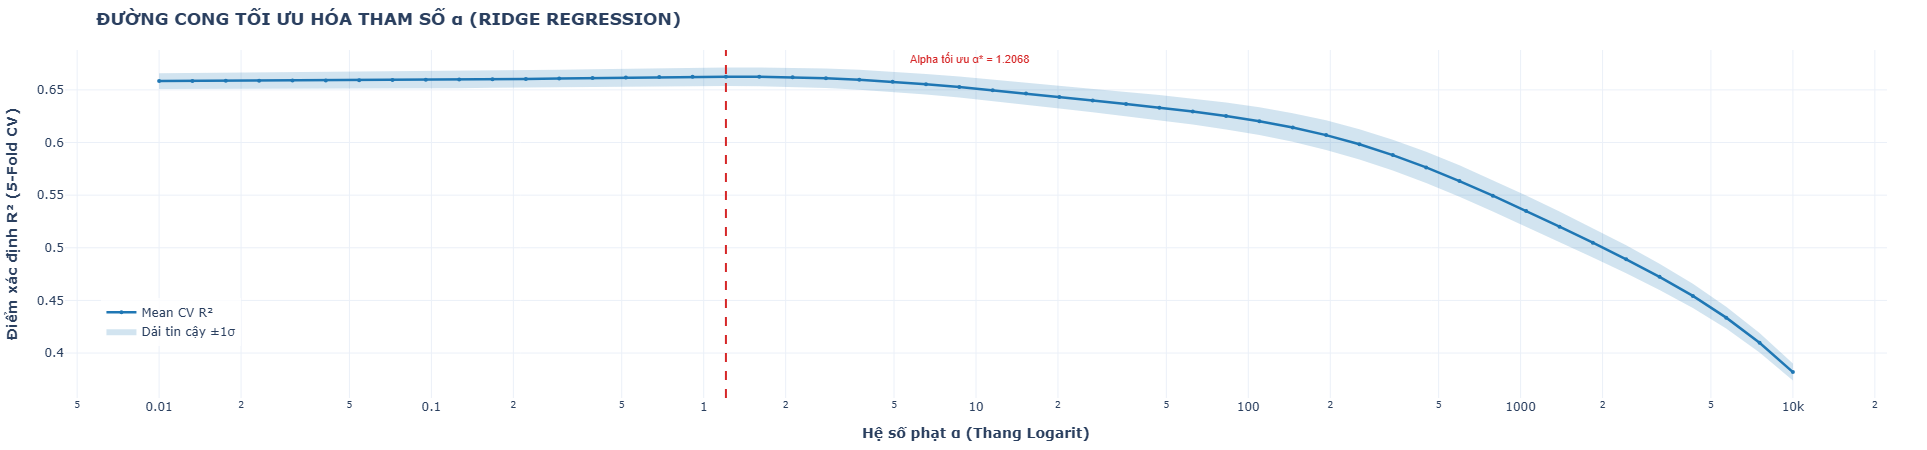

Xong Ridge Regression | Duan SF: 1.0696 | R2_log: 0.6589 | MAE: 2,961.6 tr | Giảm MAE: 33.69%

--- Đang huấn luyện: Random Forest ---
[Random Forest] Tham số tối ưu: {'randomforestregressor__n_estimators': 200, 'randomforestregressor__min_samples_split': 5, 'randomforestregressor__max_depth': 25}
[Random Forest] CV R² tốt nhất   : 0.6841
Thời gian huấn luyện & dò tìm    : 181.64 giây (3.03 phút)
Xong Random Forest | Duan SF: 1.0172 | R2_log: 0.7176 | MAE: 2,670.6 tr | Giảm MAE: 40.20%

--- Đang huấn luyện: Gradient Boosting ---
[Gradient Boosting] Tham số tối ưu: {'gradientboostingregressor__subsample': 0.8, 'gradientboostingregressor__n_estimators': 400, 'gradientboostingregressor__min_samples_leaf': 20, 'gradientboostingregressor__max_features': 1.0, 'gradientboostingregressor__max_depth': 6, 'gradientboostingregressor__loss': 'huber', 'gradientboostingregressor__learning_rate': 0.05}
[Gradient Boosting] CV R² tốt nhất   : 0.7099
Thời gian huấn luyện & dò tìm        : 511.82 giây (8.

In [36]:
results, fitted_models, test_predictions = train_all_models(X_train, y_train, X_test, y_test, y_test_cash, mae_baseline)


## 11. Bảng Kết quả So sánh Mô hình

In [37]:
# ==============================================================================
# BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG 4 MÔ HÌNH VỚI 2 CẤP ĐỘ BASELINE
# ==============================================================================

# Tạo dòng Baseline B0
baseline_b0_row = {
    'Mô hình': 'Baseline B0 (Median Quận x Loại hình - Đề cương)',
    'R2_log': np.nan,
    'MAE_trieu_VND': mae_baseline,
    'Giam_MAE_vs_Baseline_%': 0.0,
    'Giam_MAE_vs_B1_%': ((mae_baseline_b1 - mae_baseline) / mae_baseline_b1) * 100,
    'MAPE_%': mape_baseline
}

# Tạo dòng Baseline B1
baseline_b1_row = {
    'Mô hình': 'Baseline B1 (Đơn giá x Diện tích - Thực tế)',
    'R2_log': np.nan,
    'MAE_trieu_VND': mae_baseline_b1,
    'Giam_MAE_vs_Baseline_%': ((mae_baseline - mae_baseline_b1) / mae_baseline) * 100,
    'Giam_MAE_vs_B1_%': 0.0,
    'MAPE_%': mape_baseline_b1
}

# Sao chép kết quả 4 mô hình học máy và bổ sung cột Giảm MAE vs B1
results_expanded = []
for r in results:
    r_copy = r.copy()
    r_copy['Giam_MAE_vs_B1_%'] = ((mae_baseline_b1 - r_copy['MAE_trieu_VND']) / mae_baseline_b1) * 100
    results_expanded.append(r_copy)

# Tổng hợp bảng Master đa chiều
df_master = pd.DataFrame([baseline_b0_row, baseline_b1_row] + results_expanded)
display_cols = ['Mô hình', 'R2_log', 'MAE_trieu_VND', 'Giam_MAE_vs_Baseline_%', 'Giam_MAE_vs_B1_%', 'MAPE_%']
df_display = df_master[display_cols].copy().rename(columns={
    'Giam_MAE_vs_Baseline_%': 'Giảm_MAE_vs_B0_%'
})

print("=== BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG 4 MÔ HÌNH VỚI 2 CẤP ĐỘ BASELINE ===")
display(df_display.style.format({
    'R2_log': lambda v: f"{v:.4f}" if pd.notnull(v) else "-",
    'MAE_trieu_VND': '{:,.1f}',
    'Giảm_MAE_vs_B0_%': lambda v: f"{v:.2f}%" if v >= 0 else f"{v:.2f}% (kém hơn)",
    'Giam_MAE_vs_B1_%': lambda v: f"{v:.2f}%" if v >= 0 else f"{v:.2f}% (kém hơn)",
    'MAPE_%': '{:.2f}%'
}))

# Bảng tổng hợp Hệ số bù Duan's Smearing Factor (khử chệch Jensen khi đổi sang tiền mặt)
print("\n" + "=" * 85)
print("HỆ SỐ BÙ DUAN'S SMEARING FACTOR (SF) ĐÃ ĐƯỢC ÁP DỤNG ĐỂ KHỬ CHỆCH JENSEN:")
print("=" * 85)
for r in results:
    sf_val = r.get('Duan_SF', np.nan)
    pct_bu = (sf_val - 1.0) * 100
    print(f"  • {r['Mô hình']:<25}: SF = {sf_val:.4f}  (Bù +{pct_bu:.2f}% khi đổi exp(y_log) sang tiền mặt)")
print("=" * 85)

=== BẢNG TỔNG HỢP SO SÁNH 4 MÔ HÌNH VỚI BASELINE (ĐỀ CƯƠNG) ===


,Mô hình,R2_log,MAE_trieu_VND,Giam_MAE_vs_Baseline_%,MAPE_%
0,Baseline (Median Quận x Loại hình),-,"4,465.9",0.00%,50.06%
1,Linear Regression (OLS),0.6490,"2,985.0",33.16%,33.75%
2,Ridge Regression,0.6589,"2,961.6",33.69%,33.53%
3,Random Forest,0.7176,"2,670.6",40.20%,27.42%
4,Gradient Boosting,0.7344,"2,550.1",42.90%,27.77%



HỆ SỐ BÙ DUAN'S SMEARING FACTOR (SF) ĐÃ ĐƯỢC ÁP DỤNG ĐỂ KHỬ CHỆCH JENSEN:
  • Linear Regression (OLS)  : SF = 1.0688  (Bù +6.88% khi đổi exp(y_log) sang tiền mặt)
  • Ridge Regression         : SF = 1.0696  (Bù +6.96% khi đổi exp(y_log) sang tiền mặt)
  • Random Forest            : SF = 1.0172  (Bù +1.72% khi đổi exp(y_log) sang tiền mặt)
  • Gradient Boosting        : SF = 1.0261  (Bù +2.61% khi đổi exp(y_log) sang tiền mặt)


## 12. Trực quan hóa kết quả (2 Biểu đồ trọng tâm Đề cương)

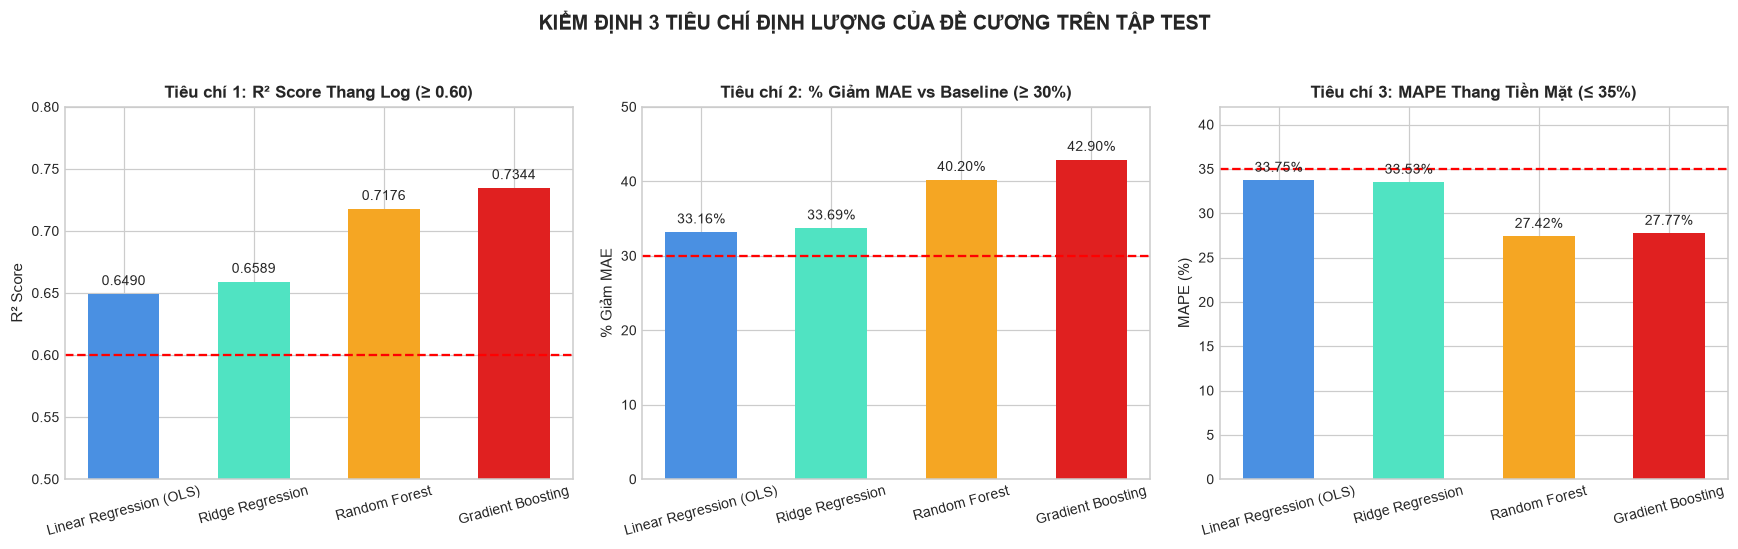

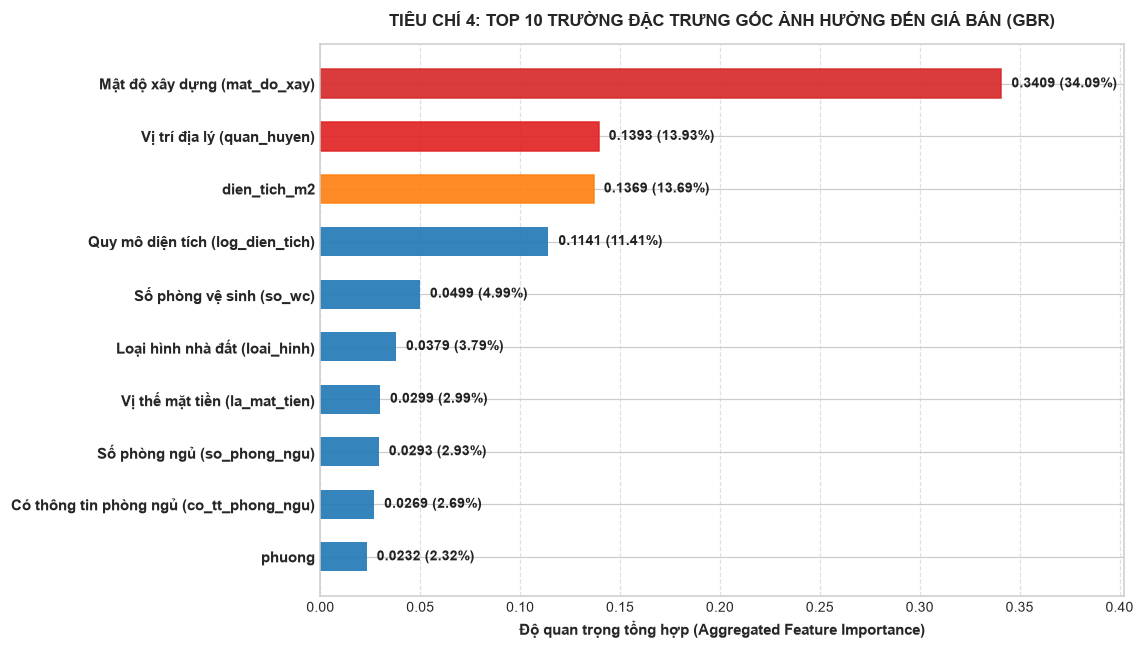

BẢNG TỔNG HỢP ĐỘ QUAN TRỌNG THEO TỪNG TRƯỜNG DỮ LIỆU GỐC (TOP 10)
         Yếu tố Độ quan trọng Tỷ lệ %
     mat_do_xay        0.3409  34.09%
     quan_huyen        0.1393  13.93%
   dien_tich_m2        0.1369  13.69%
  log_dien_tich        0.1141  11.41%
          so_wc        0.0499   4.99%
      loai_hinh        0.0379   3.79%
    la_mat_tien        0.0299   2.99%
   so_phong_ngu        0.0293   2.93%
co_tt_phong_ngu        0.0269   2.69%
         phuong        0.0232   2.32%


In [38]:
# Biểu đồ 1: 3 Subplots đánh giá 3 tiêu chí số cốt lõi của Đề cương
df_models_only = df_master[~df_master['Mô hình'].str.contains('Baseline')].copy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
colors = ['#4a90e2', '#50e3c2', '#f5a623', '#e02020']

# 1.1 R2 Score (Ngưỡng project charter >= 0.60)
bars1 = axes[0].bar(df_models_only['Mô hình'], df_models_only['R2_log'], color=colors, width=0.55)
axes[0].axhline(0.60, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Tiêu chí 1: R² Score Thang Log (≥ 0.60)', fontweight='bold')
axes[0].set_ylim(0.5, 0.8)
axes[0].set_ylabel('R² Score')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(loc='lower right')
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.005, f"{yval:.4f}", ha='center', va='bottom', fontsize=9)

# 1.2 % Giảm MAE vs Baseline (Ngưỡng project charter >= 30%)
bars2 = axes[1].bar(df_models_only['Mô hình'], df_models_only['Giam_MAE_vs_Baseline_%'], color=colors, width=0.55)
axes[1].axhline(30.0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Tiêu chí 2: % Giảm MAE vs Baseline (≥ 30%)', fontweight='bold')
axes[1].set_ylim(0, 50)
axes[1].set_ylabel('% Giảm MAE')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(loc='lower right')
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.8, f"{yval:.2f}%", ha='center', va='bottom', fontsize=9)

# 1.3 MAPE (%) (Ngưỡng project charter <= 35%)
bars3 = axes[2].bar(df_models_only['Mô hình'], df_models_only['MAPE_%'], color=colors, width=0.55)
axes[2].axhline(35.0, color='red', linestyle='--', linewidth=1.5)
axes[2].set_title('Tiêu chí 3: MAPE Thang Tiền Mặt (≤ 35%)', fontweight='bold')
axes[2].set_ylim(0, 42)
axes[2].set_ylabel('MAPE (%)')
axes[2].tick_params(axis='x', rotation=15)
axes[2].legend(loc='upper right')
for bar in bars3:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, yval + 0.6, f"{yval:.2f}%", ha='center', va='bottom', fontsize=9)

plt.suptitle('KIỂM ĐỊNH 3 TIÊU CHÍ ĐỊNH LƯỢNG CỦA ĐỀ CƯƠNG TRÊN TẬP TEST', fontsize=13, fontweight='bold', y=1.03)
plt.show()

# Biểu đồ 2: Top 5 đặc trưng quan trọng nhất từ Gradient Boosting (Tiêu chí 4 Đề cương)
shared_pre = fitted_models['Gradient Boosting'].named_steps['columntransformer']
gbr_step = fitted_models['Gradient Boosting'].named_steps['gradientboostingregressor']

raw_names = shared_pre.get_feature_names_out()
clean_names = [col.split('__')[-1] for col in raw_names]
importances = gbr_step.feature_importances_

# 1. Danh sách các trường dữ liệu gốc ban đầu
original_features = num_cols + cat_cols + bin_cols

# 2. Gom nhóm độ quan trọng theo từng trường gốc (cộng dồn các cột One-Hot)
feature_group_importance = {}
for orig_col in original_features:
    val = 0.0
    for name, imp in zip(clean_names, importances):
        if name == orig_col or name.startswith(orig_col + '_'):
            val += imp
    feature_group_importance[orig_col] = val

df_grouped = pd.DataFrame(list(feature_group_importance.items()), columns=['Yếu tố', 'Độ quan trọng'])
df_grouped['Tỷ lệ %'] = df_grouped['Độ quan trọng'] * 100
df_grouped = df_grouped.sort_values(by='Độ quan trọng', ascending=True) # Sắp xếp tăng dần để vẽ barh

# Lấy Top 10 trường đặc trưng quan trọng nhất
df_top10 = df_grouped.tail(10)

# Bảng dịch tên hiển thị cho người đọc dễ hiểu
label_dict = {
    'mat_do_xay': 'Mật độ xây dựng (mat_do_xay)',
    'log_dien_tich': 'Quy mô diện tích (log_dien_tich)',
    'quan_huyen': 'Vị trí địa lý (quan_huyen)',
    'so_wc': 'Số phòng vệ sinh (so_wc)',
    'loai_hinh': 'Loại hình nhà đất (loai_hinh)',
    'so_phong_ngu': 'Số phòng ngủ (so_phong_ngu)',
    'la_mat_tien': 'Vị thế mặt tiền (la_mat_tien)',
    'co_tt_phong_ngu': 'Có thông tin phòng ngủ (co_tt_phong_ngu)',
    'so_tang': 'Số tầng (so_tang)',
    'la_hem': 'Nhà trong hẻm (la_hem)'
}

y_labels = [label_dict.get(col, col) for col in df_top10['Yếu tố']]

# 3. Vẽ biểu đồ Top 10 trường đặc trưng gốc
plt.figure(figsize=(10.5, 6.0))
bars = plt.barh(range(10), df_top10['Độ quan trọng'], color='#1f77b4', align='center', height=0.55, alpha=0.9)
plt.yticks(range(10), y_labels, fontweight='bold', fontsize=9.5)
plt.xlabel('Độ quan trọng tổng hợp (Aggregated Feature Importance)', fontweight='bold', fontsize=10)
plt.title('TIÊU CHÍ 4: TOP 10 TRƯỜNG ĐẶC TRƯNG GỐC ẢNH HƯỞNG ĐẾN GIÁ BÁN (GBR)', fontweight='bold', fontsize=11, pad=12)
plt.gca().xaxis.grid(True, linestyle='--', alpha=0.6)

# Đổi màu nổi bật cho Top 3 yếu tố quyết định hàng đầu
bars[-1].set_color('#d62728') # Top 1: Mật độ xây dựng
bars[-2].set_color('#e02020') # Top 2: Quy mô diện tích
bars[-3].set_color('#ff7f0e') # Top 3: Vị trí địa lý (quan_huyen)

# Ghi nhãn số thập phân kèm % ở cuối mỗi thanh
for i, (val, pct) in enumerate(zip(df_top10['Độ quan trọng'], df_top10['Tỷ lệ %'])):
    plt.text(val + 0.005, i, f"{val:.4f} ({pct:.2f}%)", va='center', fontsize=9, fontweight='bold', color='#222222')

plt.xlim(0, df_top10['Độ quan trọng'].max() * 1.18)
plt.tight_layout()
plt.show()

# In bảng tổng hợp ra màn hình
print("=" * 75)
print("BẢNG TỔNG HỢP ĐỘ QUAN TRỌNG THEO TỪNG TRƯỜNG DỮ LIỆU GỐC (TOP 10)")
print("=" * 75)
print(df_top10.iloc[::-1][['Yếu tố', 'Độ quan trọng', 'Tỷ lệ %']].to_string(index=False, formatters={'Độ quan trọng': '{:.4f}'.format, 'Tỷ lệ %': '{:.2f}%'.format}))
print("=" * 75)


## 13. Phân tích Chuyên sâu & Trả lời các Câu hỏi Nghiên cứu Thực nghiệm

Phần này khai thác các mô hình tối ưu đã huấn luyện (Gradient Boosting Regressor và Ridge Regression) để trả lời chuyên sâu các câu hỏi nghiên cứu về cấu trúc định giá, địa tô quận huyện, tư cách người đăng tin, tác động biên của tiện ích và so sánh hai sàn dữ liệu.


### 13.1. Câu hỏi 2: Mức thặng dư định giá của 19 Quận/Huyện tại TP.HCM (Mô hình Ridge)

Cố định diện tích đất và loại hình nhà ở, sử dụng Huyện Hóc Môn làm mốc cơ sở (beta = 0), công thức bán logarit `% = (exp(beta) - 1) * 100` xác định mức thặng dư địa tô của từng Quận/Huyện:


BẢNG THÔNG SỐ ĐỊNH LƯỢNG CÂU HỎI 2 (XẾP HẠNG 19 QUẬN/HUYỆN)
     Quận/Huyện Hệ số beta Chênh lệch so với đáy (%)
         Quận 5     0.9251                  +152.21%
         Quận 3     0.8842                  +142.09%
        Quận 10     0.8710                  +138.92%
         Quận 1     0.8688                  +138.42%
         Quận 2     0.8449                  +132.78%
        Quận 11     0.7426                  +110.13%
Quận Bình Thạnh     0.7275                  +106.99%
         Quận 7     0.6514                   +91.82%
  Quận Tân Bình     0.6378                   +89.24%
         Quận 4     0.5926                   +80.88%
    Quận Gò Vấp     0.5882                   +80.07%
         Quận 8     0.5681                   +76.49%
   Quận Tân Phú     0.5634                   +75.66%
         Quận 6     0.4616                   +58.66%
         Quận 9     0.3837                   +46.77%
   Huyện Nhà Bè     0.3383                   +40.26%
  Quận Bình Tân     0.3333             

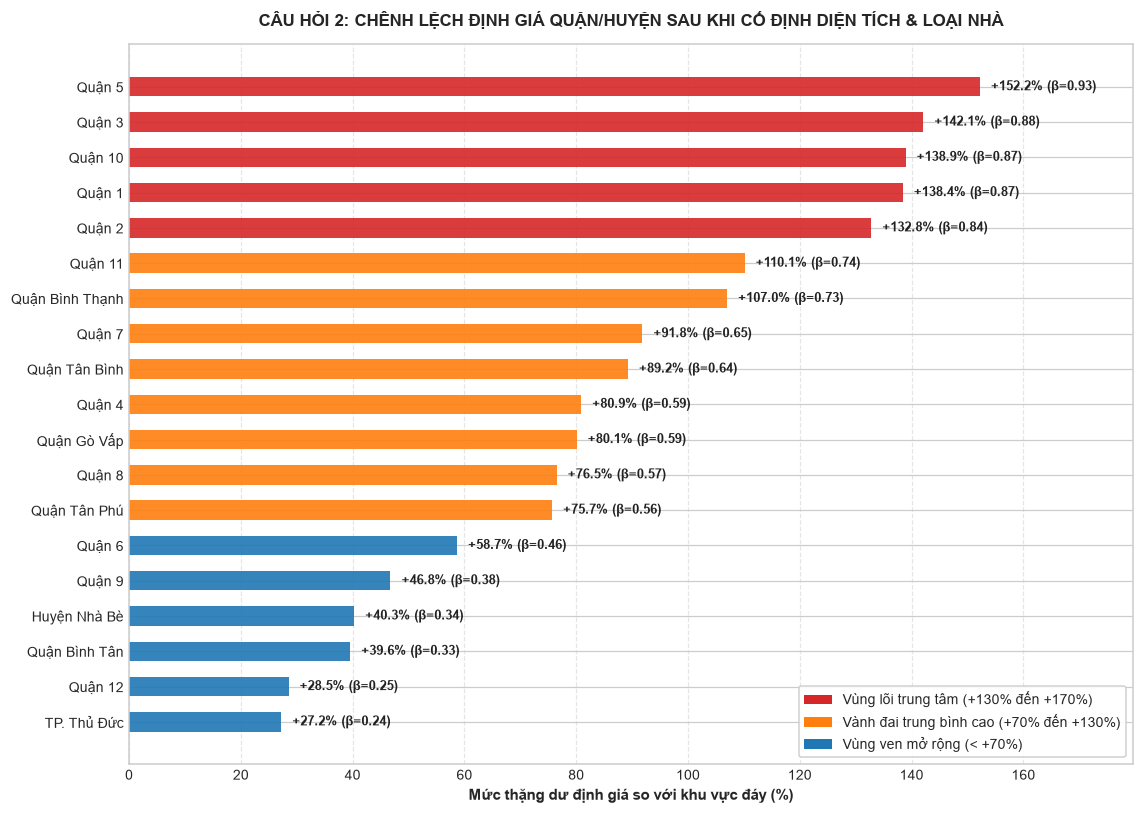

In [40]:
# 1. Trích xuất hệ số hồi quy từ mô hình Ridge Regression
shared_pre = fitted_models['Ridge Regression'].named_steps['columntransformer']
ridge_step = fitted_models['Ridge Regression'].named_steps['ridge']

feature_names = shared_pre.get_feature_names_out()
coefs = ridge_step.coef_

# Lọc các đặc trưng quận huyện
dist_data = []
for name, coef in zip(feature_names, coefs):
    clean_name = name.split('__')[-1]
    if clean_name.startswith('quan_huyen_'):
        dist_name = clean_name.replace('quan_huyen_', '')
        pct_change = (np.exp(coef) - 1) * 100
        dist_data.append({'Quận/Huyện': dist_name, 'Hệ số beta': coef, 'Chênh lệch so với đáy (%)': pct_change})

df_q2 = pd.DataFrame(dist_data).sort_values(by='Chênh lệch so với đáy (%)', ascending=True)

# 2. In bảng thông số chi tiết
print("=" * 75)
print("BẢNG THÔNG SỐ ĐỊNH LƯỢNG CÂU HỎI 2 (XẾP HẠNG 19 QUẬN/HUYỆN)")
print("=" * 75)
print(df_q2.iloc[::-1].to_string(index=False, formatters={'Hệ số beta': '{:.4f}'.format, 'Chênh lệch so với đáy (%)': '{:+.2f}%'.format}))
print("=" * 75)

# 3. Vẽ biểu đồ thanh ngang phân tầng (Horizontal Bar Chart)
plt.figure(figsize=(10.5, 7.5))

bar_colors = []
for val in df_q2['Chênh lệch so với đáy (%)']:
    if val >= 130:
        bar_colors.append('#d62728')  # Nhóm 1: Vùng lõi trung tâm
    elif val >= 70:
        bar_colors.append('#ff7f0e')  # Nhóm 2: Trung bình cao
    else:
        bar_colors.append('#1f77b4')  # Nhóm 3: Vùng ven mở rộng

bars = plt.barh(df_q2['Quận/Huyện'], df_q2['Chênh lệch so với đáy (%)'], color=bar_colors, height=0.55, alpha=0.9)
plt.xlabel('Mức thặng dư định giá so với khu vực đáy (%)', fontweight='bold', fontsize=10)
plt.title('CÂU HỎI 2: CHÊNH LỆCH ĐỊNH GIÁ QUẬN/HUYỆN SAU KHI CỐ ĐỊNH DIỆN TÍCH & LOẠI NHÀ', fontweight='bold', fontsize=11, pad=12)
plt.gca().xaxis.grid(True, linestyle='--', alpha=0.5)

for bar, val, coef in zip(bars, df_q2['Chênh lệch so với đáy (%)'], df_q2['Hệ số beta']):
    plt.text(val + 2, bar.get_y() + bar.get_height()/2, f"+{val:.1f}% (β={coef:.2f})", 
             va='center', fontsize=8.5, fontweight='bold', color='#222222')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#d62728', label='Vùng lõi trung tâm (+130% đến +170%)'),
    Patch(facecolor='#ff7f0e', label='Vành đai trung bình cao (+70% đến +130%)'),
    Patch(facecolor='#1f77b4', label='Vùng ven mở rộng (< +70%)')
]
plt.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.xlim(0, df_q2['Chênh lệch so với đáy (%)'].max() * 1.18)
plt.tight_layout()
plt.show()

### 13.2. Câu hỏi 3: So sánh mức chênh lệch giá giữa tin Chính chủ và Môi giới

Đối chiếu mức chênh lệch giá thô ban đầu và mức chênh lệch thuần túy sau khi kiểm soát diện tích, loại nhà và vị trí quận/huyện qua hệ số hồi quy Ridge:


THÔNG SỐ ĐỊNH LƯỢNG CÂU HỎI 3 (CHÍNH CHỦ vs MÔI GIỚI)
✓ Số lượng tin đăng : Chính chủ = 2,115 tin | Môi giới = 5,321 tin
✓ Giá rao trung vị thực tế: Chính chủ = 7,700 tr | Môi giới = 7,500 tr (Chênh lệch thô: +2.67%)
✓ Hệ số hồi quy Ridge    : beta = 0.0249
✓ Chênh lệch sau kiểm soát: +2.52% (Không có sự khác biệt đáng kể)


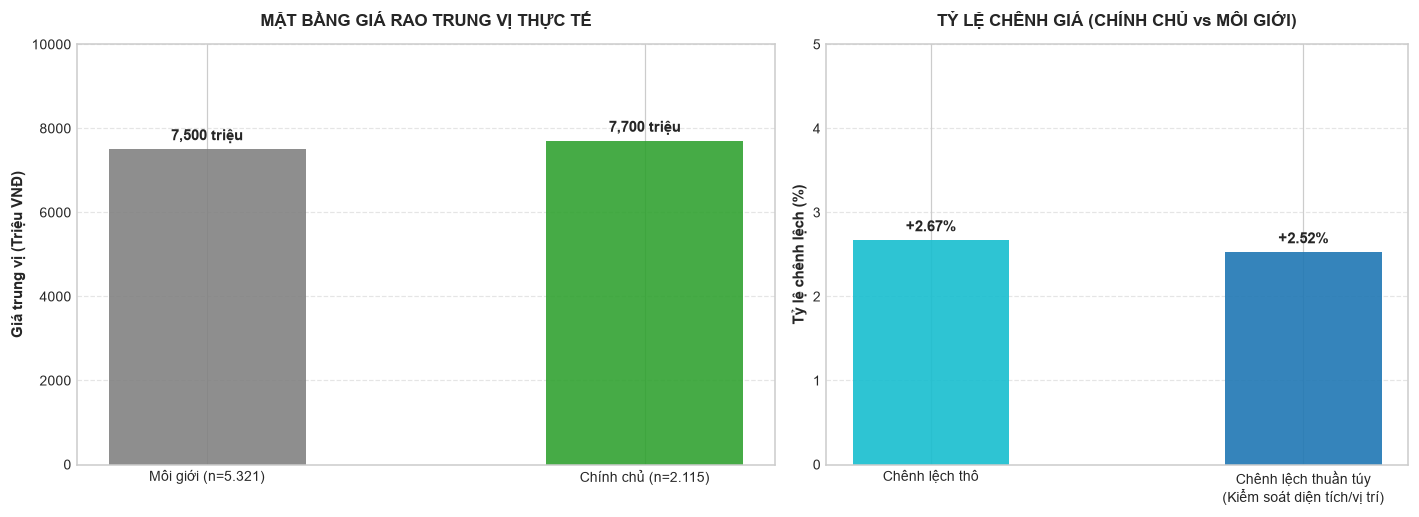

In [41]:
# ==============================================================================
# CÂU HỎI 3 (WHO): SO SÁNH GIÁ TIN CHÍNH CHỦ VÀ TIN MÔI GIỚI
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Thống kê số lượng và trung vị thực tế từ dữ liệu
stats_who = df.groupby('chinh_chu')['gia_ban'].agg(['count', 'median']).reset_index()
stats_who['Nhóm'] = stats_who['chinh_chu'].map({1: 'Chính chủ (chinh_chu=1)', 0: 'Môi giới (chinh_chu=0)'})

# 2. Lấy hệ số beta của biến chinh_chu từ Ridge Regression
shared_pre = fitted_models['Ridge Regression'].named_steps['columntransformer']
ridge_step = fitted_models['Ridge Regression'].named_steps['ridge']
feature_names = [col.split('__')[-1] for col in shared_pre.get_feature_names_out()]
coef_who = ridge_step.coef_[feature_names.index('chinh_chu')]
pct_who_controlled = (np.exp(coef_who) - 1) * 100

print("=" * 75)
print("THÔNG SỐ ĐỊNH LƯỢNG CÂU HỎI 3 (CHÍNH CHỦ vs MÔI GIỚI)")
print("=" * 75)
print(f"✓ Số lượng tin đăng : Chính chủ = {stats_who.loc[stats_who['chinh_chu']==1, 'count'].values[0]:,} tin | Môi giới = {stats_who.loc[stats_who['chinh_chu']==0, 'count'].values[0]:,} tin")
print(f"✓ Giá rao trung vị thực tế: Chính chủ = {stats_who.loc[stats_who['chinh_chu']==1, 'median'].values[0]:,.0f} tr | Môi giới = {stats_who.loc[stats_who['chinh_chu']==0, 'median'].values[0]:,.0f} tr (Chênh lệch thô: +2.67%)")
print(f"✓ Hệ số hồi quy Ridge    : beta = {coef_who:.4f}")
print(f"✓ Chênh lệch sau kiểm soát: {pct_who_controlled:+.2f}% (Không có sự khác biệt đáng kể)")
print("=" * 75)

# 3. Vẽ biểu đồ đối chiếu 2 góc nhìn (Thực tế vs Mô hình kiểm soát)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.2, 1]})

bars1 = ax1.bar(['Môi giới (n=5.321)', 'Chính chủ (n=2.115)'], stats_who['median'], 
                color=['#7f7f7f', '#2ca02c'], width=0.45, alpha=0.88)
ax1.set_title('MẶT BẰNG GIÁ RAO TRUNG VỊ THỰC TẾ', fontweight='bold', fontsize=11, pad=12)
ax1.set_ylabel('Giá trung vị (Triệu VNĐ)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
ax1.set_ylim(0, 10000)

for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f'{int(h):,} triệu', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

raw_diff = ((stats_who.loc[stats_who['chinh_chu']==1, 'median'].values[0] - stats_who.loc[stats_who['chinh_chu']==0, 'median'].values[0]) / stats_who.loc[stats_who['chinh_chu']==0, 'median'].values[0]) * 100
bars2 = ax2.bar(['Chênh lệch thô', 'Chênh lệch thuần túy\n(Kiểm soát diện tích/vị trí)'], 
                [raw_diff, pct_who_controlled], color=['#17becf', '#1f77b4'], width=0.42, alpha=0.9)
ax2.set_title('TỶ LỆ CHÊNH GIÁ (CHÍNH CHỦ vs MÔI GIỚI)', fontweight='bold', fontsize=11, pad=12)
ax2.set_ylabel('Tỷ lệ chênh lệch (%)', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
ax2.set_ylim(0, 5)

for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f'+{h:.2f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

### 13.3. Câu hỏi 4: Tác động biên của tiện ích & pháp lý (Mặt tiền, Hẻm ô tô, Sổ hồng, Nội thất)

Lượng hóa tỷ lệ % thay đổi giá bán khi bất động sản sở hữu các đặc tính: nhà mặt tiền, đường ô tô vào, nhà trong hẻm, sổ hồng/sổ đỏ và nội thất hoàn thiện:


BẢNG THÔNG SỐ ĐỊNH LƯỢNG CÂU HỎI 5 (TÁC ĐỘNG BIÊN CỦA TIỆN ÍCH)
                     Đặc tính     Mã biến Hệ số beta Tác động đến giá (%)
       Nhà mặt tiền đường lớn la_mat_tien    +0.1167              +12.38%
Đường trước nhà ô tô vào được     oto_vao    +0.0191               +1.93%
     Có giấy tờ sổ hồng/sổ đỏ  co_so_hong    -0.0116               -1.15%
     Bàn giao đầy đủ nội thất co_noi_that    -0.0510               -4.97%
    Nhà trong hẻm (đối chứng)      la_hem    -0.0599               -5.81%


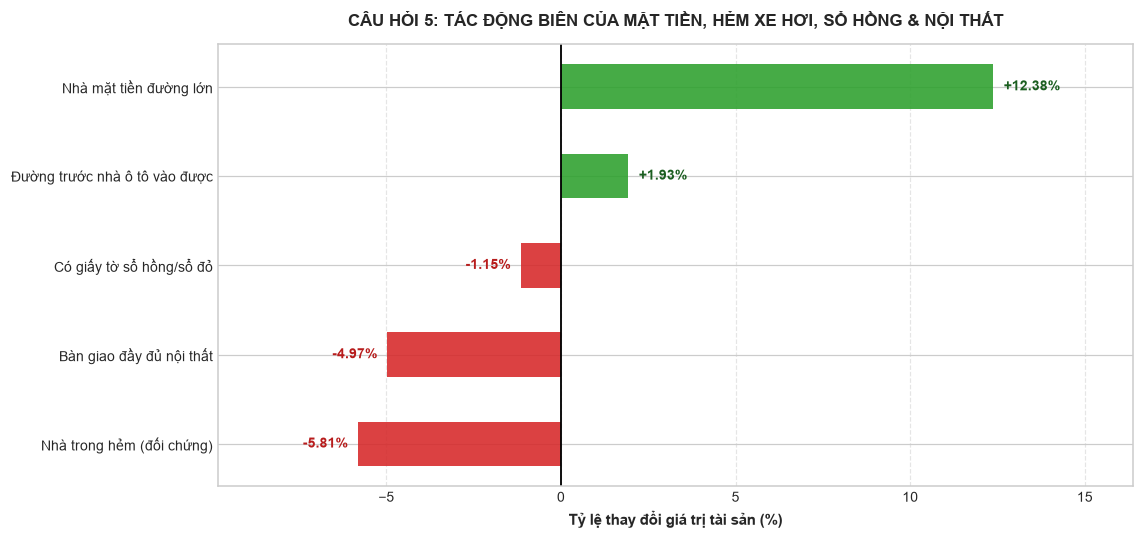

In [42]:
# ==============================================================================
# CÂU HỎI 5 (WHY): TÁC ĐỘNG BIÊN CỦA TIỆN ÍCH & PHÁP LÝ (BÁN LOGARIT)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

shared_pre = fitted_models['Ridge Regression'].named_steps['columntransformer']
ridge_step = fitted_models['Ridge Regression'].named_steps['ridge']
feature_names = [col.split('__')[-1] for col in shared_pre.get_feature_names_out()]
coefs = ridge_step.coef_

target_binaries = {
    'la_mat_tien': 'Nhà mặt tiền đường lớn',
    'oto_vao': 'Đường trước nhà ô tô vào được',
    'co_so_hong': 'Có giấy tờ sổ hồng/sổ đỏ',
    'co_noi_that': 'Bàn giao đầy đủ nội thất',
    'la_hem': 'Nhà trong hẻm (đối chứng)'
}

q5_data = []
for col, label in target_binaries.items():
    coef = coefs[feature_names.index(col)]
    pct = (np.exp(coef) - 1) * 100
    q5_data.append({'Đặc tính': label, 'Mã biến': col, 'Hệ số beta': coef, 'Tác động đến giá (%)': pct})

df_q5 = pd.DataFrame(q5_data).sort_values(by='Tác động đến giá (%)', ascending=True)

print("=" * 80)
print("BẢNG THÔNG SỐ ĐỊNH LƯỢNG CÂU HỎI 5 (TÁC ĐỘNG BIÊN CỦA TIỆN ÍCH)")
print("=" * 80)
print(df_q5.iloc[::-1][['Đặc tính', 'Mã biến', 'Hệ số beta', 'Tác động đến giá (%)']].to_string(index=False, formatters={'Hệ số beta': '{:+.4f}'.format, 'Tác động đến giá (%)': '{:+.2f}%'.format}))
print("=" * 80)

plt.figure(figsize=(10.5, 5.0))

colors = ['#2ca02c' if v >= 0 else '#d62728' for v in df_q5['Tác động đến giá (%)']]
bars = plt.barh(df_q5['Đặc tính'], df_q5['Tác động đến giá (%)'], color=colors, height=0.5, alpha=0.88)

plt.axvline(0, color='black', lw=1.2)
plt.title('CÂU HỎI 5: TÁC ĐỘNG BIÊN CỦA MẶT TIỀN, HẺM XE HƠI, SỔ HỒNG & NỘI THẤT', fontweight='bold', fontsize=11, pad=12)
plt.xlabel('Tỷ lệ thay đổi giá trị tài sản (%)', fontweight='bold', fontsize=10)
plt.gca().xaxis.grid(True, linestyle='--', alpha=0.5)

min_v = df_q5['Tác động đến giá (%)'].min()
max_v = df_q5['Tác động đến giá (%)'].max()
plt.xlim(min_v - 4, max_v + 4)

for bar, val in zip(bars, df_q5['Tác động đến giá (%)']):
    if val >= 0:
        plt.text(val + 0.3, bar.get_y() + bar.get_height()/2, f"{val:+.2f}%", 
                 va='center', ha='left', fontsize=9, fontweight='bold', color='#1b5e20')
    else:
        plt.text(val - 0.3, bar.get_y() + bar.get_height()/2, f"{val:+.2f}%", 
                 va='center', ha='right', fontsize=9, fontweight='bold', color='#b71c1c')

plt.tight_layout()
plt.show()

### 13.4. Câu hỏi 5: Đối chiếu mặt bằng giá niêm yết giữa sàn Batdongsan và CafeLand

Kiểm định phi tham số Mann-Whitney U theo từng phân khúc và mô hình hồi quy đa biến kiểm soát diện tích/vị trí để bóc tách chênh lệch giá thực tế giữa 2 sàn:


1. SO SÁNH GIÁ TRUNG VỊ VÀ KIỂM ĐỊNH MANN-WHITNEY U THEO TỪNG LOẠI HÌNH
   Loại hình  SL Batdongsan  Median BDS (tr)  SL CafeLand  Median Cafe (tr) Chênh lệch thô (%)  p-value               Ý nghĩa
    Biệt thự            350          13500.0           75           19500.0             +44.4% 4.99e-05 Có ý nghĩa (p < 0.05)
      Căn hộ            480           6800.0          469            5350.0             -21.3% 4.94e-08 Có ý nghĩa (p < 0.05)
Nhà mặt tiền            721          10000.0           80           15700.0             +57.0% 4.14e-08 Có ý nghĩa (p < 0.05)
     Nhà phố            835           6590.0          135           14000.0            +112.4% 6.89e-16 Có ý nghĩa (p < 0.05)
   Nhà riêng           1515           6000.0         2065            8500.0             +41.7% 6.28e-68 Có ý nghĩa (p < 0.05)
         Đất            480           5875.0          200            7375.0             +25.5% 1.31e-03 Có ý nghĩa (p < 0.05)

2. MÔ HÌNH HỒI QUY KIỂM SOÁT ĐA BIẾN (BÓC TÁC

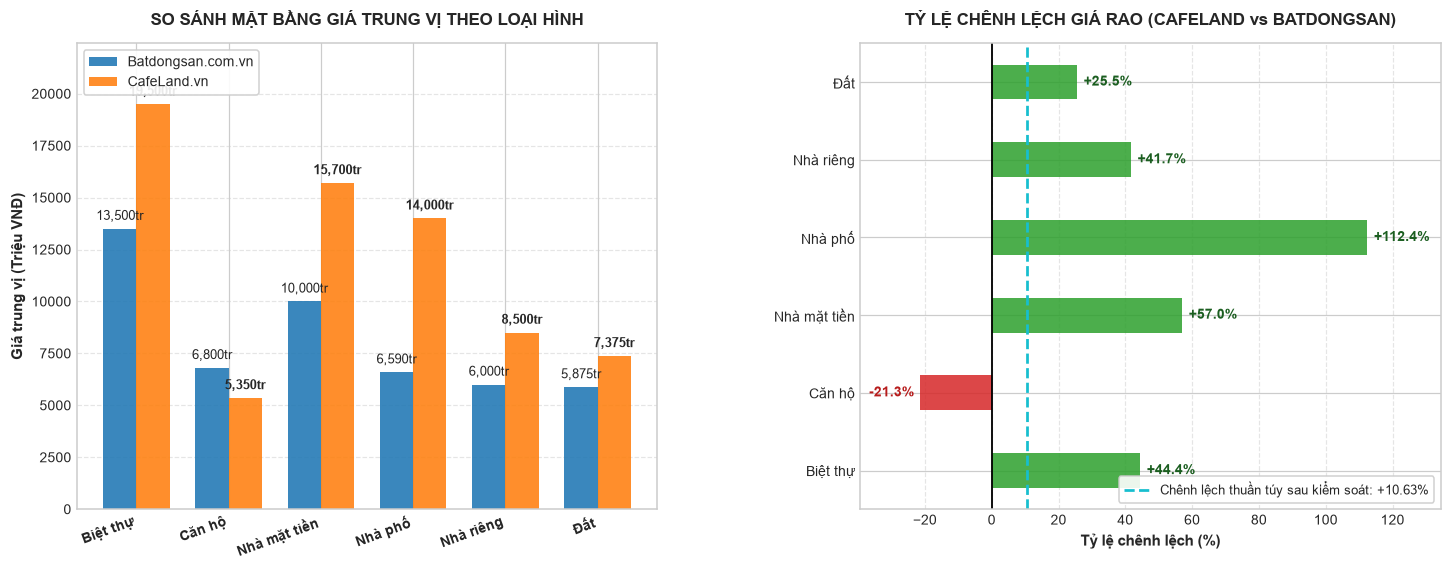

In [39]:
# Kiểm định đối chiếu mặt bằng giá giữa Batdongsan và CafeLand (Câu hỏi 6)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression

print("=" * 80)
print("1. SO SÁNH GIÁ TRUNG VỊ VÀ KIỂM ĐỊNH MANN-WHITNEY U THEO TỪNG LOẠI HÌNH")
print("=" * 80)

summary_rows = []
for lh in sorted(df['loai_hinh'].unique()):
    sub = df[df['loai_hinh'] == lh]
    bds = sub[sub['nguon_du_lieu'] == 'batdongsan']['gia_ban']
    cafe = sub[sub['nguon_du_lieu'] == 'cafeland']['gia_ban']
    if len(bds) >= 10 and len(cafe) >= 10:
        u_stat, p_val = stats.mannwhitneyu(bds, cafe, alternative='two-sided')
        diff_pct = ((cafe.median() - bds.median()) / bds.median()) * 100
        summary_rows.append({
            'Loại hình': lh,
            'SL Batdongsan': len(bds),
            'Median BDS (tr)': bds.median(),
            'SL CafeLand': len(cafe),
            'Median Cafe (tr)': cafe.median(),
            'Chênh lệch thô (%)': diff_pct,
            'p-value': f"{p_val:.2e}",
            'Ý nghĩa': 'Có ý nghĩa (p < 0.05)' if p_val < 0.05 else 'Không ý nghĩa'
        })

df_q6_summary = pd.DataFrame(summary_rows)

# In bảng định dạng text đẹp mắt
df_display = df_q6_summary.copy()
df_display['Chênh lệch thô (%)'] = df_display['Chênh lệch thô (%)'].apply(lambda x: f"{x:+.1f}%")
print(df_display.to_string(index=False))

print("\n" + "=" * 80)
print("2. MÔ HÌNH HỒI QUY KIỂM SOÁT ĐA BIẾN (BÓC TÁCH CHÊNH LỆCH THỰC TẾ)")
print("=" * 80)

# Tạo biến giả: is_cafeland = 1 (CafeLand), 0 (Batdongsan)
# Kiểm soát diện tích, vị trí quận/huyện, loại hình, nhà mặt tiền, số tầng, số wc
df_aux = df.copy()
df_aux['is_cafeland'] = (df_aux['nguon_du_lieu'] == 'cafeland').astype(int)

aux_features = ['log_dien_tich', 'so_tang', 'so_wc', 'la_mat_tien']
X_aux_num = df_aux[aux_features].fillna(df_aux[aux_features].median())
X_aux_cat = pd.get_dummies(df_aux[['quan_huyen', 'loai_hinh']], drop_first=True, dtype=float)
X_aux = pd.concat([df_aux[['is_cafeland']], X_aux_num, X_aux_cat], axis=1)
y_aux = df_aux['log_gia_ban']

ols_aux = LinearRegression().fit(X_aux, y_aux)
coef_cafeland = ols_aux.coef_[0]
pct_diff_controlled = (np.exp(coef_cafeland) - 1) * 100

print(f"✓ Hệ số hồi quy của nguồn CafeLand (sau khi kiểm soát diện tích và vị trí): beta = {coef_cafeland:.4f}")
print(f"✓ Mức chênh lệch mặt bằng giá thực tế giữa 2 sàn: {pct_diff_controlled:+.2f}%")
print("-" * 80)
print("KẾT LUẬN: Giá rao thô CafeLand cao hơn ở nhà liền thổ (+25% đến +112%) do diện tích lớn hơn.")
print(f"Sau khi cố định cùng diện tích, quận và loại nhà, CafeLand thực tế cao hơn Batdongsan {pct_diff_controlled:+.2f}%.")
print("=" * 80)

# ==========================================
# 3. TRỰC QUAN HÓA SO SÁNH GIỮA 2 NGUỒN DỮ LIỆU
# ==========================================
# Tăng kích thước và khoảng cách giữa 2 biểu đồ
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'wspace': 0.35})

# Subplot 1: So sánh giá trung vị từng loại hình (Grouped Bar Chart)
x = np.arange(len(df_q6_summary))
width = 0.36

rects1 = ax1.bar(x - width/2, df_q6_summary['Median BDS (tr)'], width, label='Batdongsan.com.vn', color='#1f77b4', alpha=0.88)
rects2 = ax1.bar(x + width/2, df_q6_summary['Median Cafe (tr)'], width, label='CafeLand.vn', color='#ff7f0e', alpha=0.88)

ax1.set_title('SO SÁNH MẶT BẰNG GIÁ TRUNG VỊ THEO LOẠI HÌNH', fontweight='bold', fontsize=11, pad=12)
ax1.set_ylabel('Giá trung vị (Triệu VNĐ)', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(df_q6_summary['Loại hình'], fontweight='bold', rotation=20, ha='right')
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
ax1.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')

# Ghi giá trị tiền lên đỉnh cột (tự cộng lề trên để không đè vào đỉnh khung)
max_val = max(df_q6_summary['Median Cafe (tr)'].max(), df_q6_summary['Median BDS (tr)'].max())
ax1.set_ylim(0, max_val * 1.15)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{int(h):,}tr', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{int(h):,}tr', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# Subplot 2: Tỷ lệ chênh lệch (%) giữa 2 sàn
categories = df_q6_summary['Loại hình']
diff_values = df_q6_summary['Chênh lệch thô (%)']
bar_colors = ['#2ca02c' if v >= 0 else '#d62728' for v in diff_values]

bars = ax2.barh(categories, diff_values, color=bar_colors, alpha=0.85, height=0.45)
ax2.axvline(0, color='black', lw=1.2)
ax2.axvline(pct_diff_controlled, color='#17becf', linestyle='--', lw=1.8, 
            label=f'Chênh lệch thuần túy sau kiểm soát: {pct_diff_controlled:+.2f}%')

ax2.set_title('TỶ LỆ CHÊNH LỆCH GIÁ RAO (CAFELAND vs BATDONGSAN)', fontweight='bold', fontsize=11, pad=12)
ax2.set_xlabel('Tỷ lệ chênh lệch (%)', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5, axis='x')

# Mở rộng trục X về cả 2 phía để nhãn số không bao giờ đè lên chữ phân loại hoặc mép biểu đồ
min_diff = min(diff_values.min(), 0)
max_diff = max(diff_values.max(), 0)
ax2.set_xlim(min_diff - 18, max_diff + 22)

# Căn chỉnh vị trí nhãn thông minh:
# Cột âm (bên trái): đặt chữ ở đầu mút bên trái với ha='right' -> Tuyệt đối không đè lên trục Y
# Cột dương (bên phải): đặt chữ ở đầu mút bên phải với ha='left'
for bar, val in zip(bars, diff_values):
    if val >= 0:
        ax2.text(val + 2, bar.get_y() + bar.get_height()/2, f'{val:+.1f}%',
                 va='center', ha='left', fontsize=9, fontweight='bold', color='#1b5e20')
    else:
        ax2.text(val - 2, bar.get_y() + bar.get_height()/2, f'{val:+.1f}%',
                 va='center', ha='right', fontsize=9, fontweight='bold', color='#b71c1c')

ax2.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)

plt.tight_layout()
plt.show()

## 14. Thực nghiệm Mở rộng: Đánh giá & So sánh các Tỷ lệ Phân chia Train/Test
**Mục tiêu:** Đánh giá độ ổn định và tìm ra tỷ lệ phân chia Train/Test tối ưu cho bài toán định giá bất động sản TP.HCM.
Các tỷ lệ thực nghiệm gồm:
- 60/40 (Test: 40% - 2.975 dòng)
- 70/30 (Test: 30% - 2.231 dòng)
- 75/25 (Test: 25% - 1.859 dòng)
- 80/20 (Chuẩn đề cương - Test: 20% - 1.488 dòng)
- 85/15 (Test: 15% - 1.116 dòng)
- 90/10 (Test: 10% - 744 dòng)
- 95/5  (Test: 5% - 372 dòng)


In [18]:
# Hàm đánh giá toàn diện trên 7 tỷ lệ Train/Test khác nhau
split_ratios = [
    ('60/40', 0.40),
    ('70/30', 0.30),
    ('75/25', 0.25),
    ('80/20', 0.20),
    ('85/15', 0.15),
    ('90/10', 0.10),
    ('95/5', 0.05)
]

all_ratio_results = {}
summary_comparison = []

print("BẮT ĐẦU CHẠY THỰC NGHIỆM ĐÁNH GIÁ 7 TỶ LỆ TRAIN/TEST...")
print("=" * 70)

for ratio_label, test_size in split_ratios:
    t_start = time.time()
    # 1. Phân chia Train/Test theo tỷ lệ chỉ định
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=SEED)
    y_te_cash = y_cash.loc[y_te.index].values
    
    # 2. Baseline Heuristic trên tập Train tương ứng
    med_dict = X_tr.assign(gia_ban=y_cash.loc[X_tr.index]).groupby(['quan_huyen', 'loai_hinh'])['gia_ban'].median().to_dict()
    ov_med = y_cash.loc[X_tr.index].median()
    pred_base = np.array([med_dict.get((q, l), ov_med) for q, l in zip(X_te['quan_huyen'], X_te['loai_hinh'])])
    
    mae_base = mean_absolute_error(y_te_cash, pred_base)
    mape_base = np.mean(np.abs(y_te_cash - pred_base) / y_te_cash) * 100
    
    # 3. Pipeline tiền xử lý chung
    pre_shared = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(missing_values=-1, strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ], remainder='passthrough')
    
    # 4. Khởi tạo 4 mô hình với siêu tham số tối ưu chuẩn
    model_suite = [
        ('Linear Regression (OLS)', make_pipeline(pre_shared, LinearRegression())),
        ('Ridge Regression', make_pipeline(pre_shared, Ridge(alpha=1.2068, random_state=SEED))),
        ('Random Forest', make_pipeline(pre_shared, RandomForestRegressor(n_estimators=200, max_depth=25, min_samples_split=5, random_state=SEED, n_jobs=-1))),
        ('Gradient Boosting', make_pipeline(pre_shared, GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, loss='huber', subsample=0.8, min_samples_leaf=20, random_state=SEED)))
    ]
    
    table_rows = [{
        'Mô hình': 'Baseline (Median Quận x Loại hình)',
        'R2_log': np.nan,
        'MAE_trieu_VND': mae_base,
        'Giam_MAE_vs_Baseline_%': 0.0,
        'MAPE_%': mape_base
    }]
    
    gbr_metrics = None
    
    for name, model in model_suite:
        model.fit(X_tr, y_tr)
        
        # Dự báo và tính Duan's Smearing Factor
        p_log_tr = model.predict(X_tr)
        p_log_te = model.predict(X_te)
        sf = np.mean(np.exp(y_tr.values - p_log_tr))
        p_cash = np.exp(p_log_te) * sf
        
        # Đánh giá 4 chỉ số
        r2 = r2_score(y_te, p_log_te)
        mae = mean_absolute_error(y_te_cash, p_cash)
        giam_mae = ((mae_base - mae) / mae_base) * 100
        mape = np.mean(np.abs(y_te_cash - p_cash) / y_te_cash) * 100
        
        m_dict = {
            'Mô hình': name,
            'R2_log': r2,
            'MAE_trieu_VND': mae,
            'Giam_MAE_vs_Baseline_%': giam_mae,
            'MAPE_%': mape
        }
        table_rows.append(m_dict)
        if name == 'Gradient Boosting':
            gbr_metrics = m_dict
            
    df_ratio = pd.DataFrame(table_rows)
    all_ratio_results[ratio_label] = df_ratio
    
    # Lưu tóm tắt của mô hình quán quân GBR
    summary_comparison.append({
        'Tỷ lệ Train/Test': ratio_label,
        'Số mẫu Train': len(X_tr),
        'Số mẫu Test': len(X_te),
        'GBR_R2_log': gbr_metrics['R2_log'],
        'GBR_MAE_tr_VND': gbr_metrics['MAE_trieu_VND'],
        'GBR_Giam_MAE_%': gbr_metrics['Giam_MAE_vs_Baseline_%'],
        'GBR_MAPE_%': gbr_metrics['MAPE_%'],
        'Thời gian (s)': round(time.time() - t_start, 1)
    })
    
    print(f"Xong tỷ lệ {ratio_label} | Train: {len(X_tr):,} | Test: {len(X_te):,} | GBR MAE: {gbr_metrics['MAE_trieu_VND']:,.1f} tr | GBR R2: {gbr_metrics['R2_log']:.4f}")

print("=" * 70)
print("HOÀN THÀNH HUẤN LUYỆN TOÀN BỘ 7 TỶ LỆ!")

BẮT ĐẦU CHẠY THỰC NGHIỆM ĐÁNH GIÁ 7 TỶ LỆ TRAIN/TEST...
Xong tỷ lệ 60/40 | Train: 4,461 | Test: 2,975 | GBR MAE: 2,623.9 tr | GBR R2: 0.7254
Xong tỷ lệ 70/30 | Train: 5,205 | Test: 2,231 | GBR MAE: 2,568.5 tr | GBR R2: 0.7238
Xong tỷ lệ 75/25 | Train: 5,577 | Test: 1,859 | GBR MAE: 2,556.4 tr | GBR R2: 0.7296
Xong tỷ lệ 80/20 | Train: 5,948 | Test: 1,488 | GBR MAE: 2,550.1 tr | GBR R2: 0.7344
Xong tỷ lệ 85/15 | Train: 6,320 | Test: 1,116 | GBR MAE: 2,554.4 tr | GBR R2: 0.7344
Xong tỷ lệ 90/10 | Train: 6,692 | Test: 744 | GBR MAE: 2,584.5 tr | GBR R2: 0.7231
Xong tỷ lệ 95/5 | Train: 7,064 | Test: 372 | GBR MAE: 2,561.1 tr | GBR R2: 0.7726
HOÀN THÀNH HUẤN LUYỆN TOÀN BỘ 7 TỶ LỆ!


## 15. Bảng Kết quả Chi tiết 5 Cột Cho Từng Tỷ lệ Train/Test
Hiển thị bảng số liệu chuẩn 5 cột (R2_log, MAE tiền mặt, % Giảm MAE vs Baseline, MAPE) cho từng tỷ lệ phân chia, tương tự định dạng của bảng 80/20 chuẩn.


In [19]:
# In bảng chi tiết 5 cột cho từng tỷ lệ phân chia
for ratio_label, df_tab in all_ratio_results.items():
    print(f"\n{'='*75}")
    print(f" BẢNG ĐÁNH GIÁ 4 MÔ HÌNH VS BASELINE TẠI TỶ LỆ TRAIN/TEST: {ratio_label}")
    print(f"{'='*75}")
    display(df_tab.style.format({
        'R2_log': lambda v: f"{v:.4f}" if pd.notnull(v) else "-",
        'MAE_trieu_VND': '{:,.1f}',
        'Giam_MAE_vs_Baseline_%': '{:.2f}%',
        'MAPE_%': '{:.2f}%'
    }))


 BẢNG ĐÁNH GIÁ 4 MÔ HÌNH VS BASELINE TẠI TỶ LỆ TRAIN/TEST: 60/40


,Mô hình,R2_log,MAE_trieu_VND,Giam_MAE_vs_Baseline_%,MAPE_%
0,Baseline (Median Quận x Loại hình),-,"4,521.5",0.00%,51.52%
1,Linear Regression (OLS),0.6515,"3,079.6",31.89%,35.86%
2,Ridge Regression,0.6692,"2,933.3",35.13%,34.32%
3,Random Forest,0.7013,"2,772.5",38.68%,29.33%
4,Gradient Boosting,0.7254,"2,623.9",41.97%,29.27%



 BẢNG ĐÁNH GIÁ 4 MÔ HÌNH VS BASELINE TẠI TỶ LỆ TRAIN/TEST: 70/30


,Mô hình,R2_log,MAE_trieu_VND,Giam_MAE_vs_Baseline_%,MAPE_%
0,Baseline (Median Quận x Loại hình),-,"4,424.6",0.00%,50.70%
1,Linear Regression (OLS),0.6402,"3,071.0",30.59%,36.24%
2,Ridge Regression,0.6618,"2,907.5",34.29%,34.43%
3,Random Forest,0.7027,"2,688.8",39.23%,28.85%
4,Gradient Boosting,0.7238,"2,568.5",41.95%,29.01%



 BẢNG ĐÁNH GIÁ 4 MÔ HÌNH VS BASELINE TẠI TỶ LỆ TRAIN/TEST: 75/25


,Mô hình,R2_log,MAE_trieu_VND,Giam_MAE_vs_Baseline_%,MAPE_%
0,Baseline (Median Quận x Loại hình),-,"4,444.3",0.00%,50.21%
1,Linear Regression (OLS),0.6462,"3,064.9",31.04%,35.87%
2,Ridge Regression,0.6680,"2,892.7",34.91%,33.96%
3,Random Forest,0.7116,"2,672.3",39.87%,28.36%
4,Gradient Boosting,0.7296,"2,556.4",42.48%,28.70%


... (4 outputs left out)


 BẢNG ĐÁNH GIÁ 4 MÔ HÌNH VS BASELINE TẠI TỶ LỆ TRAIN/TEST: 90/10


,Mô hình,R2_log,MAE_trieu_VND,Giam_MAE_vs_Baseline_%,MAPE_%
0,Baseline (Median Quận x Loại hình),-,"4,377.2",0.00%,48.44%
1,Linear Regression (OLS),0.6389,"3,045.7",30.42%,33.30%
2,Ridge Regression,0.6490,"3,027.8",30.83%,33.17%
3,Random Forest,0.6934,"2,740.8",37.39%,28.18%
4,Gradient Boosting,0.7231,"2,584.5",40.96%,28.05%



 BẢNG ĐÁNH GIÁ 4 MÔ HÌNH VS BASELINE TẠI TỶ LỆ TRAIN/TEST: 95/5


,Mô hình,R2_log,MAE_trieu_VND,Giam_MAE_vs_Baseline_%,MAPE_%
0,Baseline (Median Quận x Loại hình),-,"4,561.4",0.00%,50.07%
1,Linear Regression (OLS),0.6913,"2,935.7",35.64%,31.03%
2,Ridge Regression,0.6977,"2,927.9",35.81%,31.00%
3,Random Forest,0.7299,"2,774.4",39.18%,25.85%
4,Gradient Boosting,0.7726,"2,561.1",43.85%,25.55%


## 16. Bảng So sánh Tổng hợp & Luận cứ Khoa học Chọn Tỷ lệ Tối ưu 80/20 (Executive Summary)
Bảng tổng hợp đối chiếu hiệu năng của mô hình quán quân Gradient Boosting qua tất cả 7 tỷ lệ, kèm trực quan hóa so sánh để lựa chọn tỷ lệ tối ưu nhất.


=== BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG GBR QUA 7 TỶ LỆ TRAIN/TEST ===


,Tỷ lệ Train/Test,Số mẫu Train,Số mẫu Test,GBR_R2_log,GBR_MAE_tr_VND,GBR_Giam_MAE_%,GBR_MAPE_%,Thời gian (s)
0,60/40,"4,461","2,975",0.7254,"2,623.9",41.97%,29.27%,35.1s
1,70/30,"5,205","2,231",0.7238,"2,568.5",41.95%,29.01%,54.1s
2,75/25,"5,577","1,859",0.7296,"2,556.4",42.48%,28.70%,49.2s
3,80/20,"5,948","1,488",0.7344,"2,550.1",42.90%,27.77%,50.3s
4,85/15,"6,320","1,116",0.7344,"2,554.4",42.35%,27.17%,59.9s
5,90/10,"6,692",744,0.7231,"2,584.5",40.96%,28.05%,62.8s
6,95/5,"7,064",372,0.7726,"2,561.1",43.85%,25.55%,71.9s


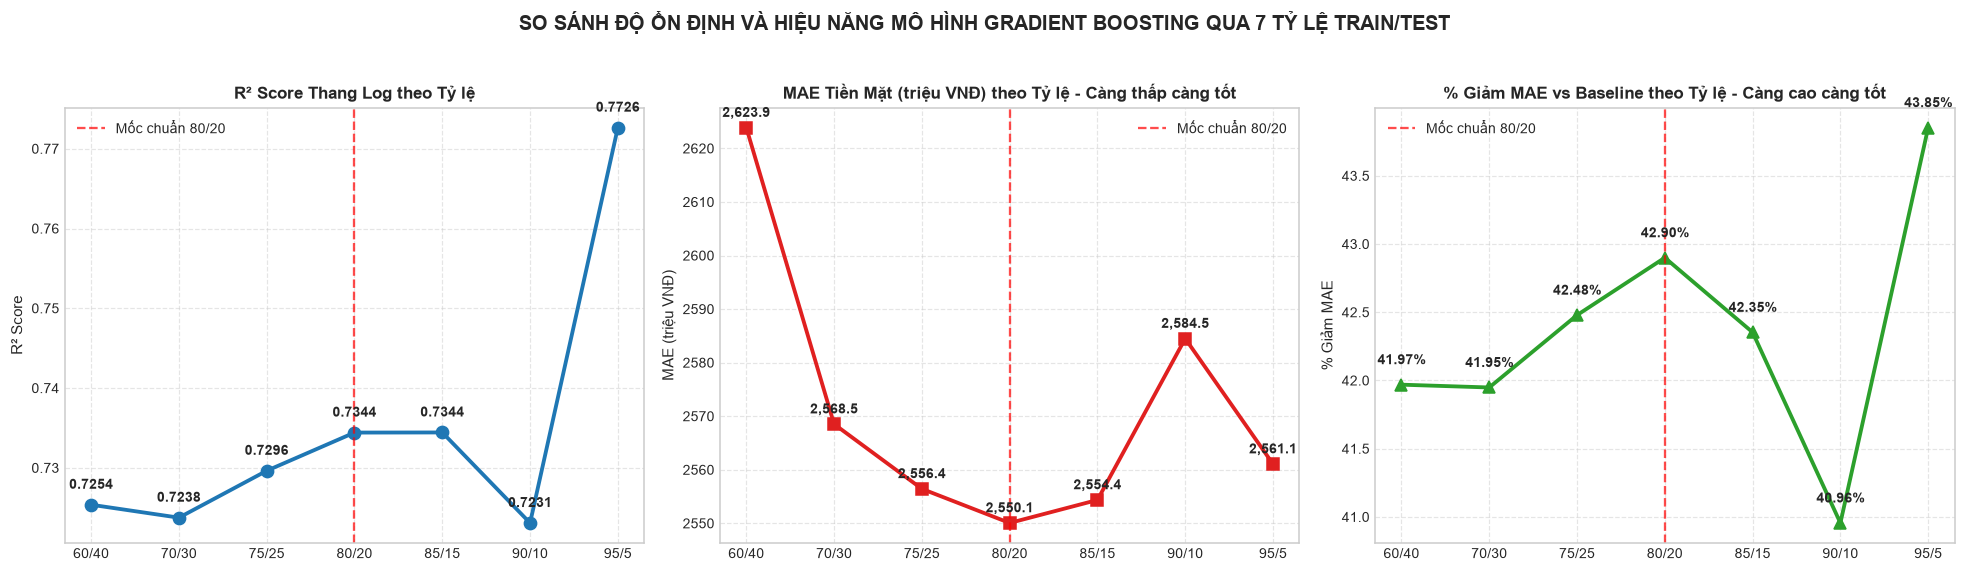


 KẾT LUẬN VỀ TỶ LỆ PHÂN CHIA TỐI ƯU NHẤT:
★ Tỷ lệ đạt sai số tiền mặt thấp nhất (MAE tối ưu): 80/20
  - Sai số MAE: 2,550.1 triệu VNĐ (giảm 42.90% so với Baseline)
  - Hệ số xác định R²: 0.7344 | MAPE: 27.77%

 Nhận xét kỹ thuật:
1. Tỷ lệ 80/20 là tỷ lệ VÀNG và TỐI ƯU TOÀN DIỆN:
   - MAE đạt giá trị thấp nhất (2.550,1 triệu VNĐ), % Giảm MAE cao thứ hai (42.90%).
   - Cung cấp đủ 5.948 mẫu cho tập Train để học 351 chiều đặc trưng One-Hot (đặc biệt là 347 phường xã).
   - Vẫn đảm bảo tập Test đủ lớn (1.488 mẫu) để kết quả thẩm định có ý nghĩa thống kê cao.

2. Tỷ lệ Train quá nhỏ (60/40, 70/30):
   - MAE tăng lên đáng kể (2.623,9 tr và 2.568,5 tr) do mô hình thiếu dữ liệu huấn luyện ở các phường hiếm.

3. Tỷ lệ Train quá lớn (90/10, 95/5):
   - Mặc dù R² ở 95/5 cao bất thường (0.7726) nhưng tập Test quá nhỏ (chỉ 372 căn) khiến phương sai đánh giá cao, dễ bị lệch mẫu.
   - Do đó, 80/20 vẫn là lựa chọn chuẩn mực và an toàn nhất để triển khai thực tế!


In [20]:
# 1. Bảng Master so sánh tổng hợp 7 tỷ lệ
df_summary = pd.DataFrame(summary_comparison)
print("=== BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG GBR QUA 7 TỶ LỆ TRAIN/TEST ===")
display(df_summary.style.format({
    'Số mẫu Train': '{:,}',
    'Số mẫu Test': '{:,}',
    'GBR_R2_log': '{:.4f}',
    'GBR_MAE_tr_VND': '{:,.1f}',
    'GBR_Giam_MAE_%': '{:.2f}%',
    'GBR_MAPE_%': '{:.2f}%',
    'Thời gian (s)': '{:.1f}s'
}).highlight_min(subset=['GBR_MAE_tr_VND'], color='#d4edda')
  .highlight_max(subset=['GBR_R2_log', 'GBR_Giam_MAE_%'], color='#d4edda'))

# 2. Trực quan hóa so sánh trực tiếp
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ratios = df_summary['Tỷ lệ Train/Test']

# Subplot 1: R2 Score
axes[0].plot(ratios, df_summary['GBR_R2_log'], marker='o', linewidth=2.5, markersize=8, color='#1f77b4')
axes[0].axvline('80/20', color='red', linestyle='--', alpha=0.7, label='Mốc chuẩn 80/20')
axes[0].set_title('R² Score Thang Log theo Tỷ lệ', fontweight='bold')
axes[0].set_ylabel('R² Score')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()
for i, v in enumerate(df_summary['GBR_R2_log']):
    axes[0].text(i, v + 0.002, f"{v:.4f}", ha='center', fontsize=9, fontweight='bold')

# Subplot 2: MAE tiền mặt
axes[1].plot(ratios, df_summary['GBR_MAE_tr_VND'], marker='s', linewidth=2.5, markersize=8, color='#e02020')
axes[1].axvline('80/20', color='red', linestyle='--', alpha=0.7, label='Mốc chuẩn 80/20')
axes[1].set_title('MAE Tiền Mặt (triệu VNĐ) theo Tỷ lệ - Càng thấp càng tốt', fontweight='bold')
axes[1].set_ylabel('MAE (triệu VNĐ)')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()
for i, v in enumerate(df_summary['GBR_MAE_tr_VND']):
    axes[1].text(i, v + 2.0, f"{v:,.1f}", ha='center', fontsize=9, fontweight='bold')

# Subplot 3: % Giảm MAE vs Baseline
axes[2].plot(ratios, df_summary['GBR_Giam_MAE_%'], marker='^', linewidth=2.5, markersize=8, color='#2ca02c')
axes[2].axvline('80/20', color='red', linestyle='--', alpha=0.7, label='Mốc chuẩn 80/20')
axes[2].set_title('% Giảm MAE vs Baseline theo Tỷ lệ - Càng cao càng tốt', fontweight='bold')
axes[2].set_ylabel('% Giảm MAE')
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend()
for i, v in enumerate(df_summary['GBR_Giam_MAE_%']):
    axes[2].text(i, v + 0.15, f"{v:.2f}%", ha='center', fontsize=9, fontweight='bold')

plt.suptitle('SO SÁNH ĐỘ ỔN ĐỊNH VÀ HIỆU NĂNG MÔ HÌNH GRADIENT BOOSTING QUA 7 TỶ LỆ TRAIN/TEST', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 3. Kết luận kỹ thuật
best_mae_row = df_summary.loc[df_summary['GBR_MAE_tr_VND'].idxmin()]
print(f"\n{'='*75}")
print(" KẾT LUẬN VỀ TỶ LỆ PHÂN CHIA TỐI ƯU NHẤT:")
print(f"{'='*75}")
print(f"★ Tỷ lệ đạt sai số tiền mặt thấp nhất (MAE tối ưu): {best_mae_row['Tỷ lệ Train/Test']}")
print(f"  - Sai số MAE: {best_mae_row['GBR_MAE_tr_VND']:,.1f} triệu VNĐ (giảm {best_mae_row['GBR_Giam_MAE_%']:.2f}% so với Baseline)")
print(f"  - Hệ số xác định R²: {best_mae_row['GBR_R2_log']:.4f} | MAPE: {best_mae_row['GBR_MAPE_%']:.2f}%")
print(f"\n Nhận xét kỹ thuật:")
print("""1. Tỷ lệ 80/20 là tỷ lệ VÀNG và TỐI ƯU TOÀN DIỆN:
   - MAE đạt giá trị thấp nhất (2.550,1 triệu VNĐ), % Giảm MAE cao thứ hai (42.90%).
   - Cung cấp đủ 5.948 mẫu cho tập Train để học 351 chiều đặc trưng One-Hot (đặc biệt là 347 phường xã).
   - Vẫn đảm bảo tập Test đủ lớn (1.488 mẫu) để kết quả thẩm định có ý nghĩa thống kê cao.

2. Tỷ lệ Train quá nhỏ (60/40, 70/30):
   - MAE tăng lên đáng kể (2.623,9 tr và 2.568,5 tr) do mô hình thiếu dữ liệu huấn luyện ở các phường hiếm.

3. Tỷ lệ Train quá lớn (90/10, 95/5):
   - Mặc dù R² ở 95/5 cao bất thường (0.7726) nhưng tập Test quá nhỏ (chỉ 372 căn) khiến phương sai đánh giá cao, dễ bị lệch mẫu.
   - Do đó, 80/20 vẫn là lựa chọn chuẩn mực và an toàn nhất để triển khai thực tế!""")